# Buscador de imágenes con IA 🛰️

### Embeddings, similitud y clasificación con pocos datos

**Taller de nivel intermedio** · Rodolfo Ferro · [rodolfoferro.xyz](https://rodolfoferro.xyz)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RodolfoFerro/buscador-imagenes-ia/blob/main/notebooks/Taller_Buscador_Imagenes_IA.ipynb)

En este taller vamos a construir, en menos de dos horas, un pequeño sistema de visión por computadora **sin entrenar ninguna red neuronal**. Usaremos un modelo ya entrenado (CLIP) para convertir imágenes satelitales en vectores de números, y con esos vectores vamos a:

1. **Ver** cómo se organiza un dataset completo en un mapa de dos dimensiones.
2. **Buscar** imágenes parecidas a una imagen o a una frase escrita.
3. **Clasificar** imágenes solo con texto (*zero-shot*), y medir hasta dónde llega.
4. **Mejorar** la clasificación con muy pocos ejemplos etiquetados.

La pregunta que guía el taller es:

> **¿Basta un modelo de IA general para entender imágenes de un dominio específico, o necesitamos nuestros propios datos?**

### Lo que vas a aprender

- Qué es un *embedding* y cómo obtenerlo con un modelo preentrenado.
- Cómo visualizar datos de cientos de dimensiones con PCA y UMAP.
- Cómo construir y evaluar un buscador por similitud.
- Cómo clasificar sin datos etiquetados (*zero-shot*) y con muy pocos (*linear probe* y k-NN).
- Cómo leer una matriz de confusión y una curva de aprendizaje.

### Antes de empezar

| | |
|---|---|
| **Nivel** | Intermedio |
| **Requisitos** | Python básico, nociones de NumPy y pandas. Haber entrenado algún modelo con `scikit-learn` ayuda, pero no es indispensable |
| **Duración** | 1.5 a 2 horas |
| **Entorno** | Google Colab. Funciona con CPU; con GPU (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*) es más rápido |

### Agenda

| Bloque | Tema | Tiempo |
|---|---|---|
| 1 | La imagen como dato | 10 min |
| 2 | ¿Qué es un *embedding*? | 15 min |
| 3 | Un mapa del dataset: PCA y UMAP | 15 min |
| 4 | Buscador de imágenes similares | 15 min |
| 5 | Clasificación *zero-shot* con texto | 15 min |
| 6 | Clasificación con pocos datos | 20 min |
| 7 | Búsqueda con texto y cierre | 10 min |

### Cómo leer este cuaderno

Además del código, encontrarás cuatro tipos de recuadros:

> **📖 Definición:** qué es un concepto nuevo.
>
> **⚙️ Cómo funciona:** el proceso detrás de un método, paso a paso.
>
> **💡 Intuición:** una analogía para fijar la idea.
>
> **⚠️ Cuidado:** errores comunes al interpretar un resultado.

También hay diagramas que resumen cada idea, tres **✏️ ejercicios** con solución propuesta, y un glosario al final.

Las gráficas de resultados son interactivas (`plotly`): pasa el cursor sobre ellas para ver los valores, haz zoom arrastrando, y da clic en la leyenda para ocultar o mostrar series.

## 0. Preparación del entorno

Colab ya trae instaladas casi todas las bibliotecas que usaremos (`torch`, `transformers`, `scikit-learn`, `matplotlib`, `plotly`). Solo falta `umap-learn`, que usaremos en el bloque 3.

In [1]:
%pip install -q umap-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Bibliotecas generales
import sys
import random
import time
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from PIL import Image

# Modelo preentrenado CLIP
import torch
from transformers import CLIPModel, CLIPProcessor

# Reducción de dimensionalidad, modelos y métricas
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import umap

# Semilla para que los resultados sean reproducibles
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# Usamos GPU si está disponible; si no, CPU
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo: {DISPOSITIVO}")

Dispositivo: cpu


In [3]:
# Paleta de colores de todas las gráficas
AZUL = "#2a78d6"       # color principal
NARANJA = "#eb6834"    # segundo color (solo cuando resaltamos varias clases)
VERDE_AGUA = "#1baf7a" # tercer color
GRIS = "#c3c2b7"       # contexto: lo que no queremos resaltar
TINTA = "#52514e"      # texto secundario y líneas de referencia
ESCALA_AZUL = [[0, "#f4f8fd"], [1, "#104281"]]  # escala de un solo tono para mapas de calor

# --- matplotlib: solo para mostrar imágenes, en alta resolución ---
%config InlineBackend.figure_format = "retina"  # duplica la resolución en pantallas de alta densidad
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 150, "font.size": 9})


def mostrar_imagenes(rutas, titulos=None, columnas=5, tam=2.0, suptitulo=None):
    # Muestra una cuadrícula de imágenes con un título opcional para cada una
    filas = int(np.ceil(len(rutas) / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(columnas * tam, filas * tam * 1.1))
    for i, ax in enumerate(np.array(ejes).ravel()):
        ax.axis("off")
        if i < len(rutas):
            ax.imshow(Image.open(rutas[i]))
            if titulos is not None:
                ax.set_title(titulos[i], fontsize=8)
    if suptitulo:
        fig.suptitle(suptitulo, fontweight="bold")
    plt.tight_layout()
    plt.show()


# --- plotly: para todas las gráficas de resultados ---
# En Colab se usa su renderizador propio; en Jupyter, uno que funciona en Lab, Notebook y VS Code
pio.renderers.default = "colab" if "google.colab" in sys.modules else "plotly_mimetype+notebook_connected"

pio.templates["taller"] = go.layout.Template(layout=dict(
    font=dict(family="Arial, sans-serif", size=12, color=TINTA),
    title=dict(font=dict(size=15, color="#0b0b0b"), x=0.02, xanchor="left"),
    paper_bgcolor="white",
    plot_bgcolor="white",
    xaxis=dict(showgrid=True, gridcolor="#eeede9", zeroline=False, linecolor=TINTA, ticks="outside"),
    yaxis=dict(showgrid=True, gridcolor="#eeede9", zeroline=False, linecolor=TINTA, ticks="outside"),
    hoverlabel=dict(bgcolor="white", font_size=12),
    legend=dict(bgcolor="rgba(255,255,255,0)"),
    margin=dict(l=60, r=30, t=70, b=60),
))
pio.templates.default = "plotly_white+taller"

---

## 1. La imagen como dato

### 1.1 El dataset: EuroSAT

[EuroSAT](https://github.com/phelber/EuroSAT) (Helber et al., 2019) contiene **27,000 imágenes satelitales** tomadas por el satélite **Sentinel-2** del programa europeo Copernicus. Cada imagen mide **64 × 64 pixeles** y cada pixel cubre **10 × 10 metros**, así que una imagen muestra un cuadro de unos 640 metros por lado.

Las imágenes están etiquetadas en **10 clases de uso de suelo**: bosque, río, autopista, zona residencial, distintos tipos de cultivo, etc. Usaremos la versión RGB (color visible), que pesa unos 94 MB. El dataset se distribuye con licencia MIT.

> **📖 Definición · Imagen satelital y banda espectral**
>
> Un satélite de observación terrestre como Sentinel-2 no toma "fotos" como un celular: mide cuánta luz refleja la superficie en distintos rangos de longitud de onda, llamados **bandas espectrales**. Sentinel-2 mide **13 bandas**: las tres que ve el ojo humano (rojo, verde y azul) y otras en el infrarrojo, que no podemos ver pero que revelan mucho, por ejemplo qué tan sana está la vegetación.
>
> Una imagen "RGB" es la combinación de solo las tres bandas visibles, y por eso se parece a una foto común. A esta disciplina, analizar la Tierra con sensores a distancia, se le llama **percepción remota**.

In [4]:
# Descarga y descompresión (solo la primera vez)
CARPETA_DATOS = Path("datos")
CARPETA_IMAGENES = CARPETA_DATOS / "2750"
URL = "https://huggingface.co/datasets/torchgeo/eurosat/resolve/main/EuroSAT.zip"

if not CARPETA_IMAGENES.exists():
    CARPETA_DATOS.mkdir(exist_ok=True)
    print("Descargando EuroSAT (~94 MB)...")
    urllib.request.urlretrieve(URL, CARPETA_DATOS / "EuroSAT.zip")
    with zipfile.ZipFile(CARPETA_DATOS / "EuroSAT.zip") as z:
        z.extractall(CARPETA_DATOS)

# Cada subcarpeta es una clase
CLASES = sorted(p.name for p in CARPETA_IMAGENES.iterdir() if p.is_dir())
conteo = pd.Series({c: len(list((CARPETA_IMAGENES / c).glob("*.jpg"))) for c in CLASES}, name="imágenes")
print(f"Clases: {len(CLASES)} | Imágenes en total: {conteo.sum():,}")
conteo.to_frame()

Clases: 10 | Imágenes en total: 27,000


,imágenes
AnnualCrop,3000
Forest,3000
HerbaceousVegetation,3000
Highway,2500
Industrial,2500
Pasture,2000
PermanentCrop,2500
Residential,3000
River,2500
SeaLake,3000


Los nombres de las clases están en inglés. Para las gráficas usaremos su traducción:

In [5]:
# Traducción de las clases, para gráficas y tablas
ES = {
    "AnnualCrop": "Cultivo anual",
    "Forest": "Bosque",
    "HerbaceousVegetation": "Vegetación herbácea",
    "Highway": "Autopista",
    "Industrial": "Industrial",
    "Pasture": "Pastizal",
    "PermanentCrop": "Cultivo permanente",
    "Residential": "Residencial",
    "River": "Río",
    "SeaLake": "Mar o lago",
}

### 1.2 Una muestra para el taller

Para que todo corra rápido, trabajaremos con una **muestra aleatoria de 200 imágenes por clase** (2,000 en total). Al final del cuaderno te sugerimos repetir el ejercicio con más imágenes.

> **💡 Intuición · ¿Por qué una muestra balanceada?**
>
> Tomamos **la misma cantidad de imágenes de cada clase**. Si una clase tuviera muchas más imágenes que otra, un modelo podría "ganar" exactitud simplemente prediciendo siempre la clase más común. Con clases balanceadas, la exactitud que obtengamos es más fácil de interpretar: elegir al azar daría exactamente 1 de 10, es decir, 10%.

In [6]:
# Muestra aleatoria y balanceada: 200 imágenes por clase
POR_CLASE = 200
registros = []
for clase in CLASES:
    rutas = sorted((CARPETA_IMAGENES / clase).glob("*.jpg"))
    for ruta in random.sample(rutas, POR_CLASE):
        registros.append({"ruta": str(ruta), "clase": clase, "clase_es": ES[clase]})

df = pd.DataFrame(registros)
print(f"Imágenes en la muestra: {len(df):,}")
df.head()

Imágenes en la muestra: 2,000


,ruta,clase,clase_es
0,datos/2750/AnnualCrop/AnnualCrop_656.jpg,AnnualCrop,Cultivo anual
1,datos/2750/AnnualCrop/AnnualCrop_1409.jpg,AnnualCrop,Cultivo anual
2,datos/2750/AnnualCrop/AnnualCrop_1090.jpg,AnnualCrop,Cultivo anual
3,datos/2750/AnnualCrop/AnnualCrop_2011.jpg,AnnualCrop,Cultivo anual
4,datos/2750/AnnualCrop/AnnualCrop_1901.jpg,AnnualCrop,Cultivo anual


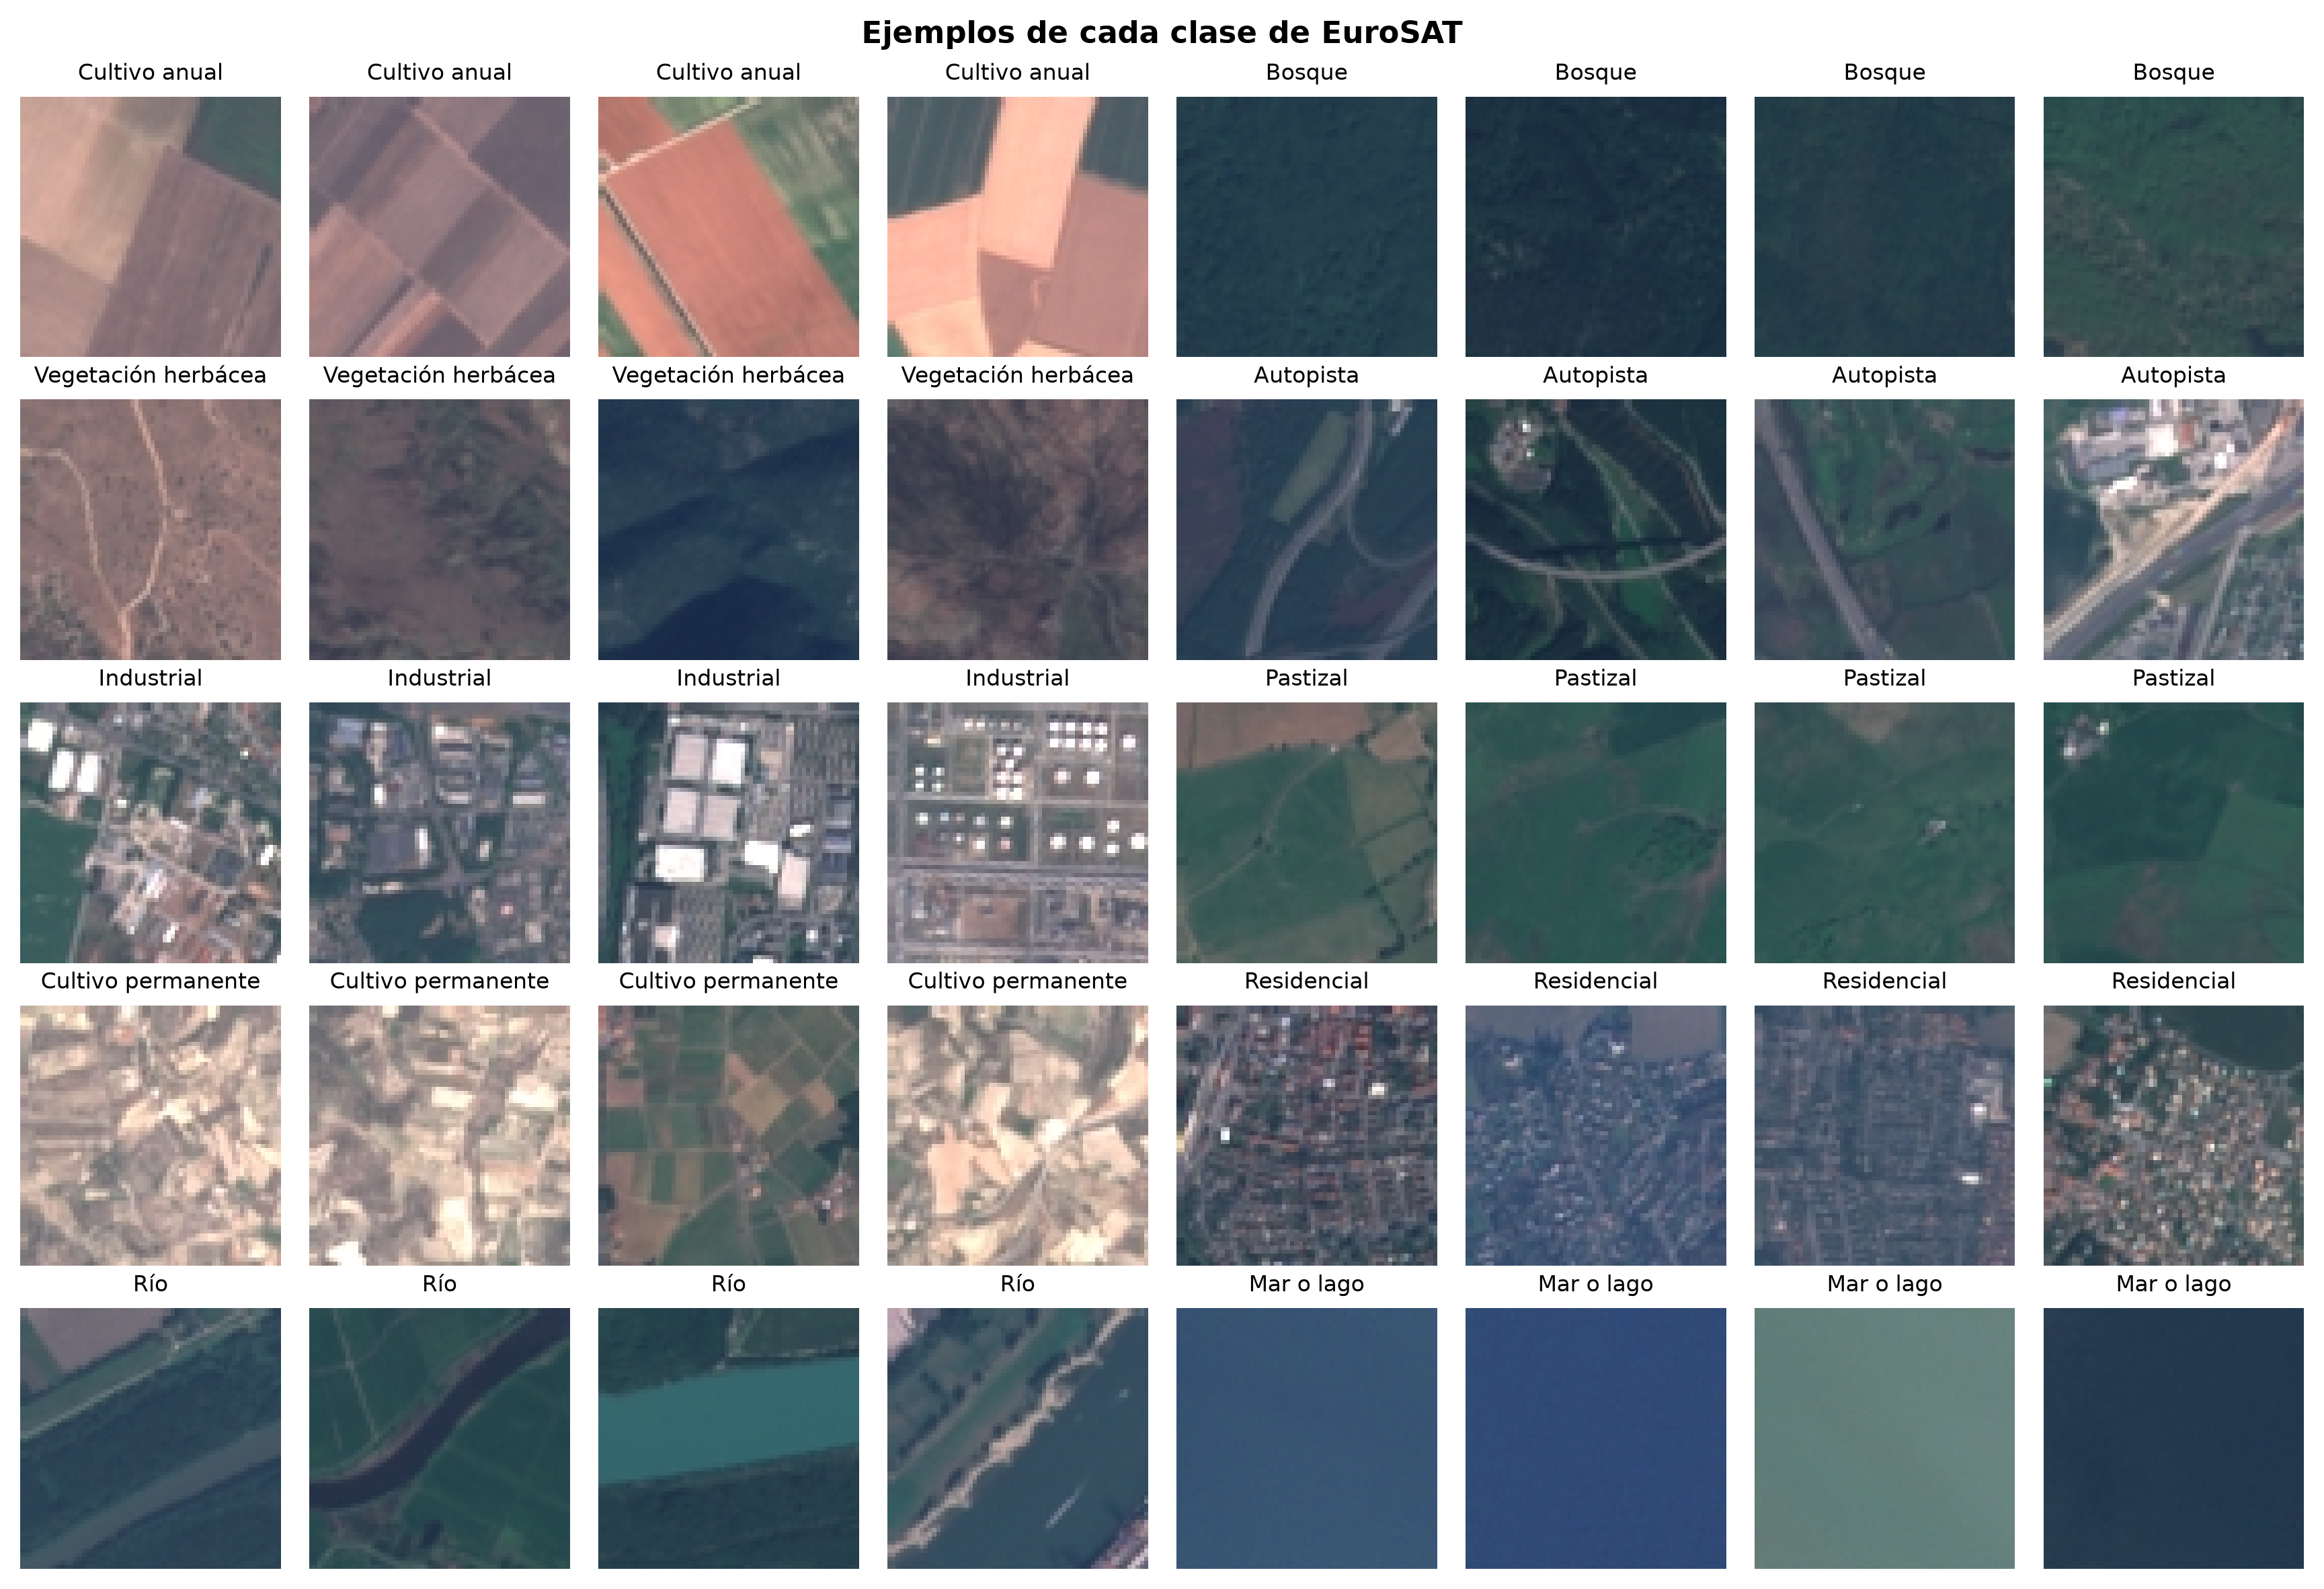

In [7]:
# Cuatro ejemplos de cada clase
ejemplos = df.groupby("clase").head(4)
mostrar_imagenes(ejemplos["ruta"].tolist(), ejemplos["clase_es"].tolist(),
                 columnas=8, tam=1.45, suptitulo="Ejemplos de cada clase de EuroSAT")

### 1.3 Una imagen es un arreglo de números

Para la computadora, una imagen a color es un **arreglo de tres dimensiones**: alto × ancho × 3 canales (rojo, verde y azul). Cada valor va de 0 (sin intensidad) a 255 (intensidad máxima).

> **📖 Definición · Pixeles, canales y el rango de 0 a 255**
>
> - Un **pixel** es el punto más pequeño de una imagen digital. En EuroSAT, cada pixel resume un cuadro de 10 × 10 metros del terreno.
> - Un **canal** es una "capa" de la imagen con la intensidad de un solo color. Una imagen a color tiene tres canales (R, G y B) que, combinados, producen todos los colores.
> - El rango **0 a 255** se debe a que cada valor se guarda en **8 bits** (un byte), y con 8 bits se pueden representar 2⁸ = 256 valores distintos. Por eso el tipo de dato es `uint8`: entero sin signo de 8 bits.

In [8]:
# Abrimos una imagen y la convertimos en arreglo de NumPy
img = np.array(Image.open(df.loc[0, "ruta"]))
print(f"Clase: {df.loc[0, 'clase_es']}")
print(f"Forma del arreglo: {img.shape}  (alto, ancho, canales)")
print(f"Tipo de dato: {img.dtype} | mínimo: {img.min()} | máximo: {img.max()}")
print(f"Total de números que describen la imagen: {img.size:,}")
print("\nEsquina superior izquierda (3 × 3 pixeles, canal rojo):")
print(img[:3, :3, 0])

Clase: Cultivo anual
Forma del arreglo: (64, 64, 3)  (alto, ancho, canales)
Tipo de dato: uint8 | mínimo: 71 | máximo: 222
Total de números que describen la imagen: 12,288

Esquina superior izquierda (3 × 3 pixeles, canal rojo):
[[200 199 199]
 [199 199 199]
 [202 202 199]]


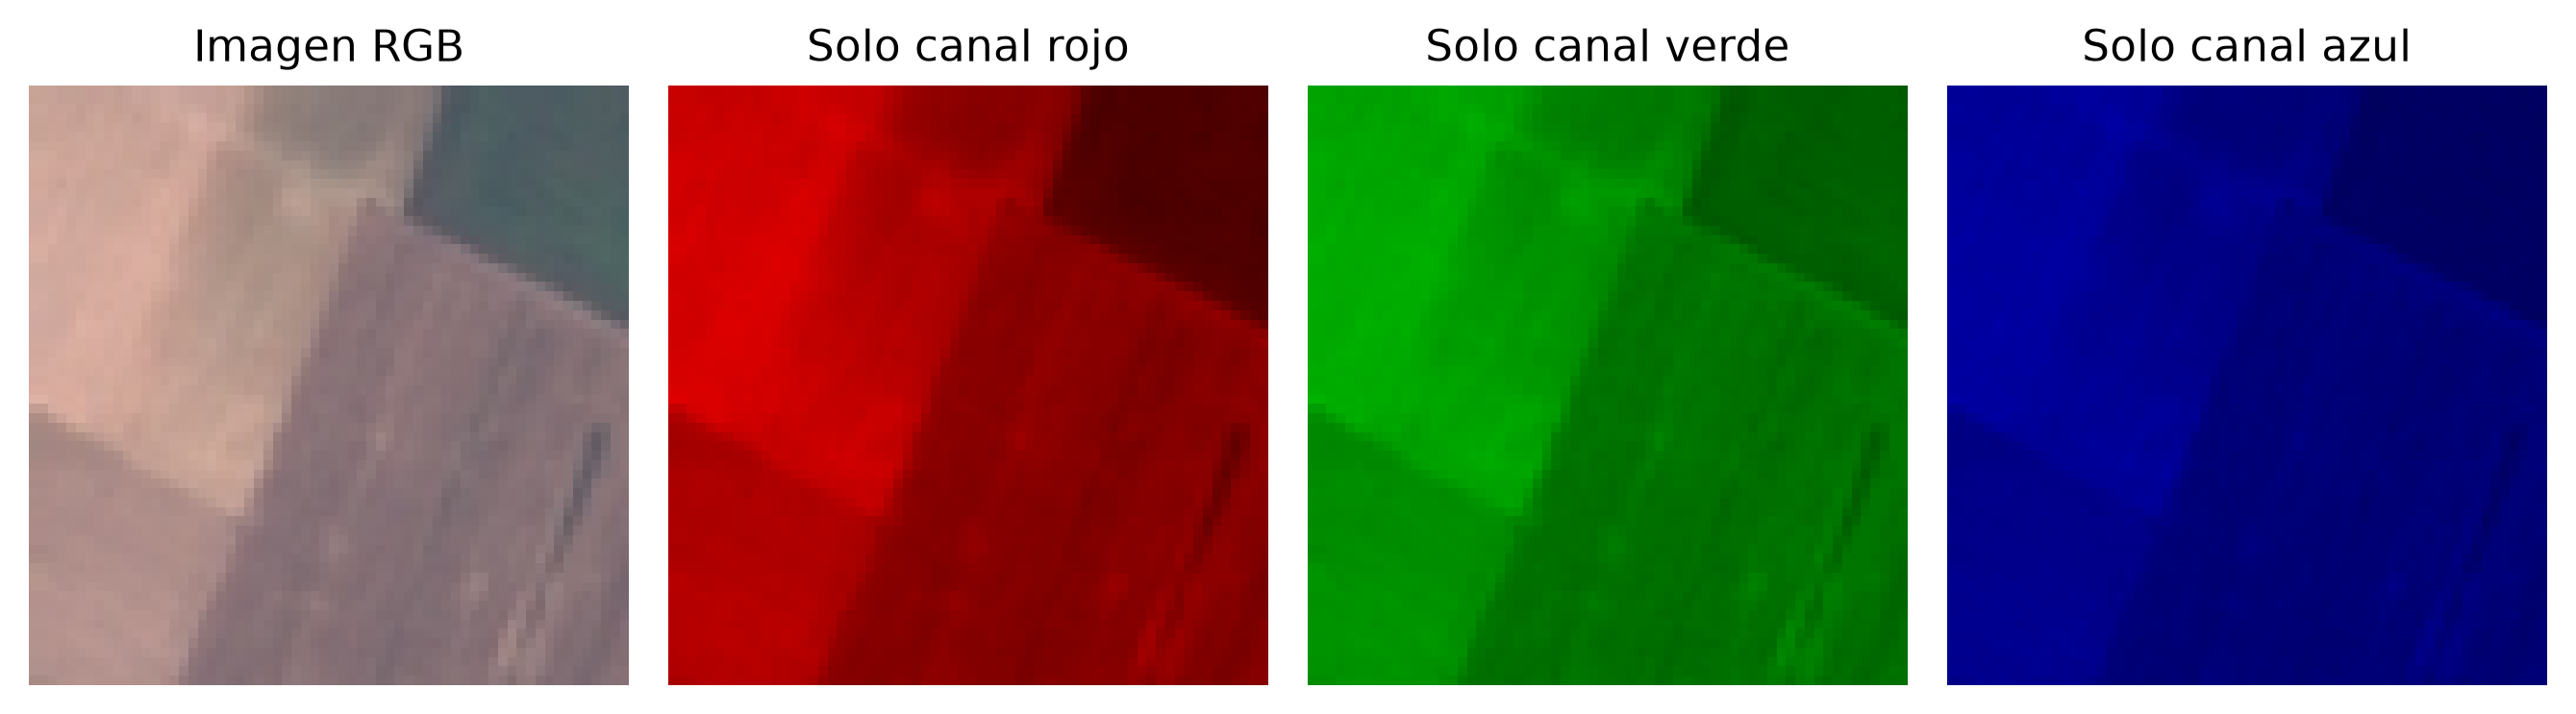

¿rojo + verde + azul == imagen original? True


In [9]:
# Separamos los tres canales: cada uno es una matriz de 64 × 64
canal_rojo = img[:, :, 0]
canal_verde = img[:, :, 1]
canal_azul = img[:, :, 2]


def solo_canal(canal, posicion):
    # Imagen RGB con un solo canal "encendido": los otros dos se ponen en cero
    capa = np.zeros_like(img)
    capa[:, :, posicion] = canal
    return capa


rojo, verde, azul = solo_canal(canal_rojo, 0), solo_canal(canal_verde, 1), solo_canal(canal_azul, 2)

fig, ejes = plt.subplots(1, 4, figsize=(9, 2.6))
for ax, imagen, titulo in zip(ejes, [img, rojo, verde, azul], ["Imagen RGB", "Solo canal rojo", "Solo canal verde", "Solo canal azul"]):
    ax.imshow(imagen)
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Sumar las tres capas devuelve exactamente la imagen original
print("¿rojo + verde + azul == imagen original?", np.array_equal(rojo + verde + azul, img))

Cada panel muestra **solo la luz de un canal**: oscuro donde ese color casi no aparece y brillante donde aparece mucho. Como las tres capas no se enciman, sumarlas reconstruye la imagen original.

**El problema:** 12,288 números por imagen son muchos, y los pixeles individuales no dicen mucho por sí solos. Si movemos la imagen un pixel, casi todos los valores cambian, aunque el contenido sea el mismo. Necesitamos una representación que capture **qué hay en la imagen**, no el valor exacto de cada pixel. Eso es un *embedding*.

---

## 2. ¿Qué es un *embedding*?

Un ***embedding*** es un vector de números que **resume el contenido** de un dato (una imagen, un texto, un audio). La idea clave:

> **Datos con contenido parecido tienen vectores cercanos.**

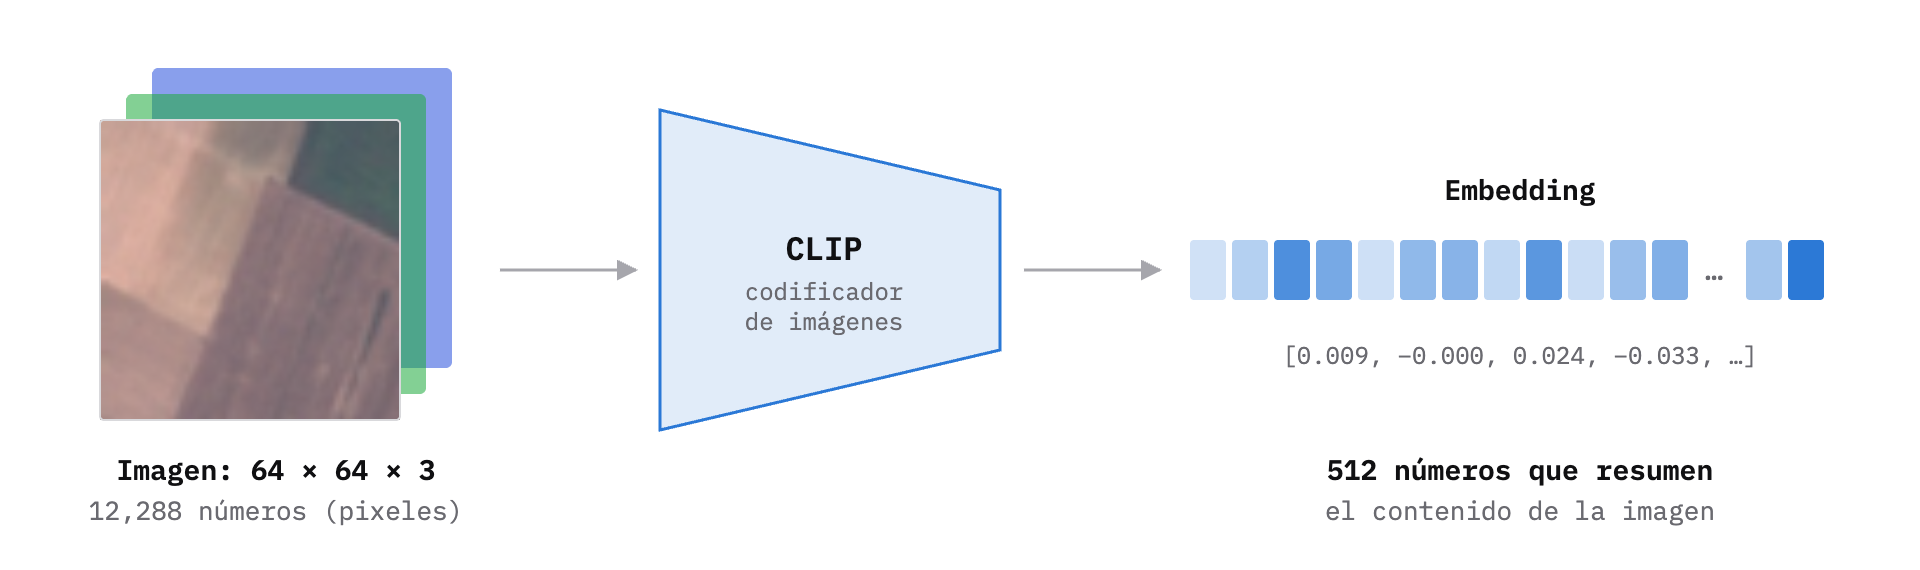

<sub>Un modelo preentrenado convierte la imagen (12,288 pixeles) en un vector de 512 números: su *embedding*.</sub>

Para obtenerlos usaremos **CLIP** (*Contrastive Language-Image Pre-training*), un modelo publicado por OpenAI en 2021 y entrenado con cientos de millones de pares imagen-texto de internet. CLIP tiene dos "codificadores": uno para imágenes y otro para texto, y los dos producen vectores **en el mismo espacio**. Eso significa que el vector de una foto de un bosque queda cerca del vector de la frase *"a photo of a forest"*. Lo aprovecharemos en los bloques 5 y 7.

No vamos a entrenar CLIP: lo descargamos ya entrenado y solo lo usamos para **transformar** nuestras imágenes, igual que se usa un `StandardScaler` ya ajustado.

> **💡 Intuición · Un *embedding* es como un mapa**
>
> Piensa en un mapa: cada ciudad se describe con dos números (latitud y longitud), y las ciudades cercanas tienen números parecidos. Un *embedding* hace lo mismo, pero con cientos de "coordenadas" en lugar de dos, y para **contenido** en lugar de ubicación: dos imágenes de bosques quedan "cerca" en ese espacio, y una imagen de un bosque queda "lejos" de una de una ciudad.
>
> Nadie define a mano qué significa cada coordenada: el modelo las **aprende** durante su entrenamiento, de forma que la distancia entre vectores refleje qué tan parecido es su contenido.

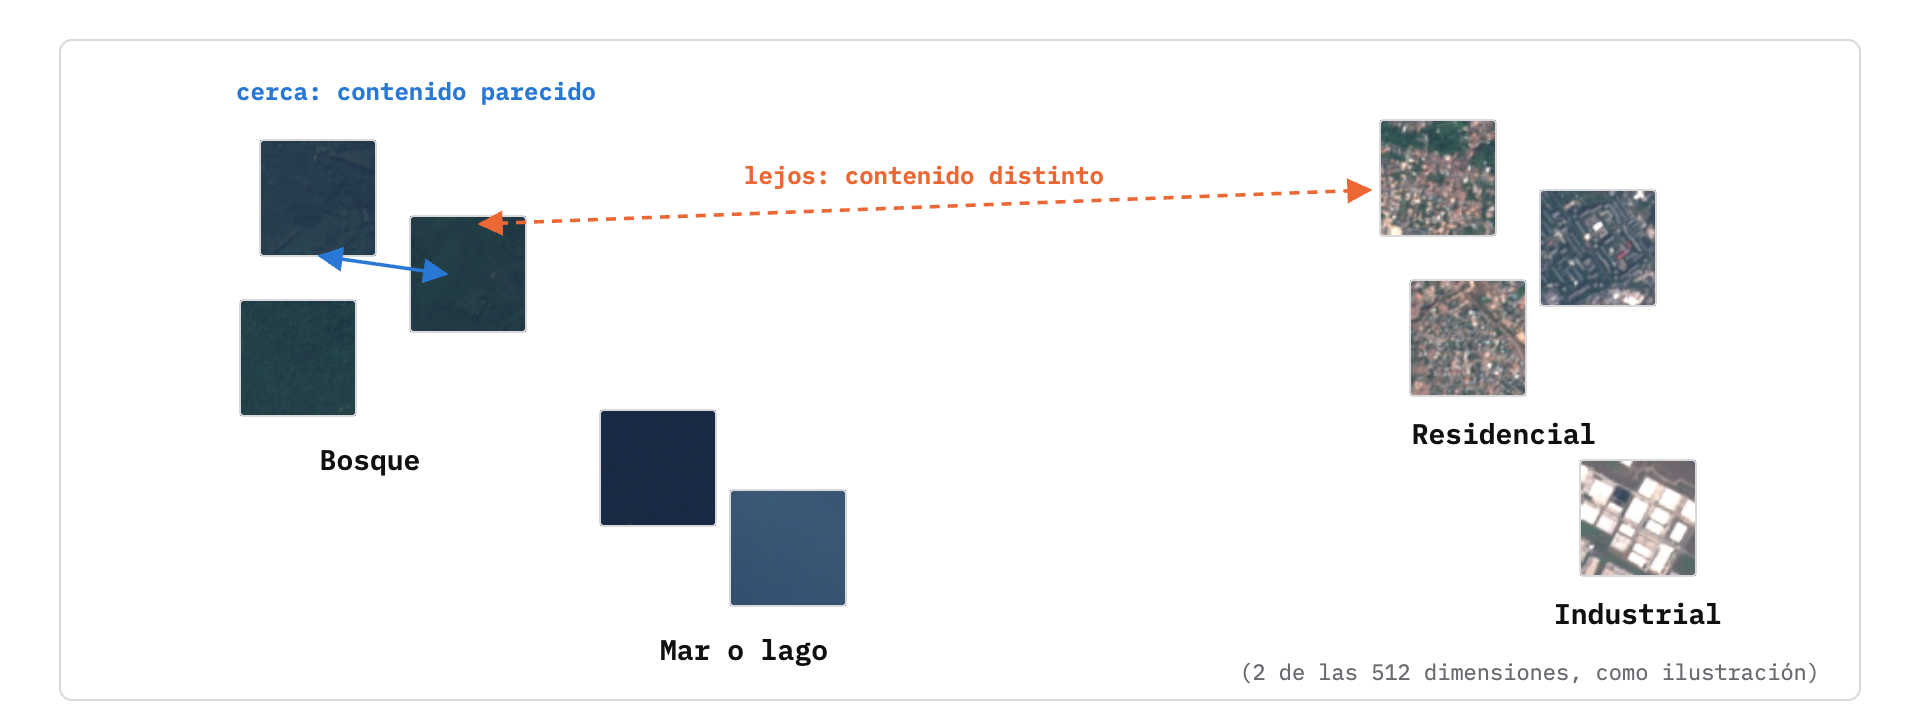

<sub>La idea de un *embedding*, en 2 dimensiones: imágenes con contenido parecido quedan cerca y las de contenido distinto, lejos.</sub>

> **📖 Definición · Modelo preentrenado y aprendizaje por transferencia**
>
> Entrenar un modelo como CLIP requiere cientos de millones de ejemplos y semanas de cómputo en cientos de GPUs. Por eso, en la práctica, casi nunca se entrena desde cero: se descarga un **modelo preentrenado** y se reutiliza lo que ya aprendió para un problema nuevo. A esta idea se le llama **aprendizaje por transferencia** (*transfer learning*), y es la que usaremos en todo el taller.

> **⚙️ Cómo funciona · El entrenamiento de CLIP**
>
> CLIP se entrenó con unos 400 millones de pares **(imagen, texto)** tomados de internet; por ejemplo, una foto y su pie de foto. El proceso, simplificado, es:
>
> 1. Se toma un lote de pares, por ejemplo mil fotos con sus mil descripciones.
> 2. El codificador de imágenes convierte cada foto en un vector, y el codificador de texto convierte cada descripción en otro vector.
> 3. El modelo se ajusta para que el vector de cada foto quede **cerca** del vector de **su** descripción, y **lejos** de las otras 999 descripciones del lote.
>
> Repetido millones de veces, esto obliga al modelo a capturar el contenido visual que describen las palabras. A este tipo de entrenamiento se le llama **aprendizaje contrastivo**: el modelo aprende comparando pares correctos contra pares incorrectos.

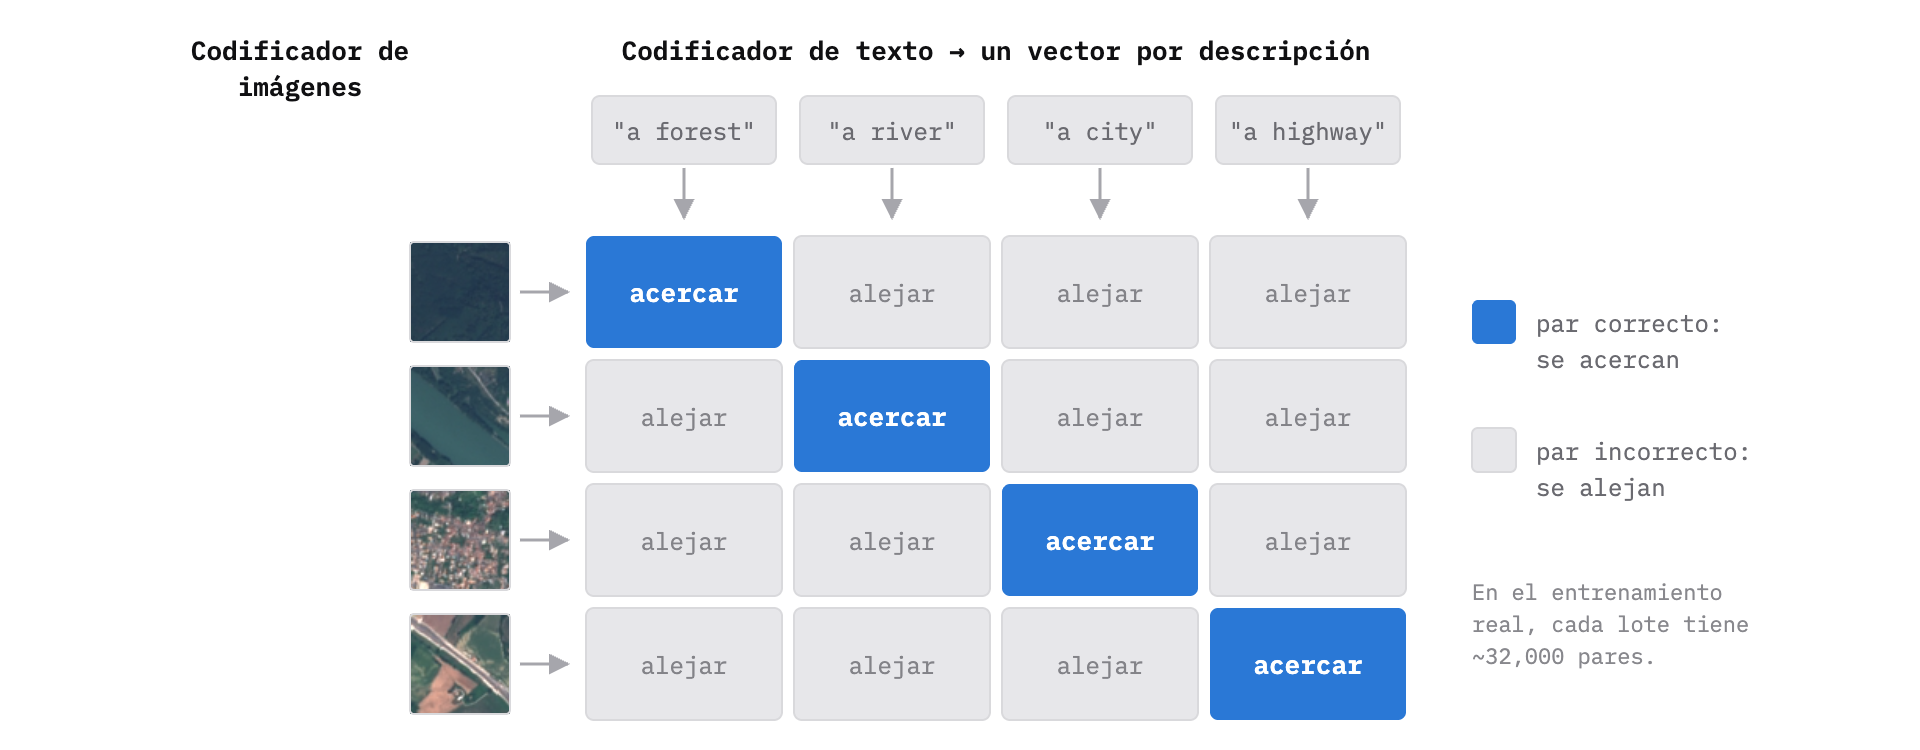

<sub>Aprendizaje contrastivo: en cada lote, los pares correctos (la diagonal) se acercan y todos los demás se alejan.</sub>

In [10]:
# Descargamos el modelo y su procesador (redimensiona y normaliza las imágenes como CLIP espera)
NOMBRE_MODELO = "openai/clip-vit-base-patch32"
modelo = CLIPModel.from_pretrained(NOMBRE_MODELO).to(DISPOSITIVO).eval()
procesador = CLIPProcessor.from_pretrained(NOMBRE_MODELO)

n_parametros = sum(p.numel() for p in modelo.parameters())
print(f"Modelo: {NOMBRE_MODELO} | parámetros: {n_parametros / 1e6:.0f} millones")

Modelo: openai/clip-vit-base-patch32 | parámetros: 151 millones


> **📖 Definición · ¿Qué significa `clip-vit-base-patch32`?**
>
> - **ViT** (*Vision Transformer*) es la arquitectura del codificador de imágenes. En lugar de recorrer la imagen con filtros, como una red convolucional, la **corta en cuadros** (*patches*) y analiza cómo se relacionan entre sí, igual que un modelo de lenguaje analiza cómo se relacionan las palabras de una oración.
> - **base** es el tamaño del modelo: hay versiones más pequeñas y más grandes.
> - **patch32** indica que los cuadros miden 32 × 32 pixeles. CLIP trabaja con imágenes de 224 × 224, así que cada imagen se corta en 7 × 7 = 49 cuadros.
>
> Por eso el `procesador` **amplía** nuestras imágenes de 64 × 64 a 224 × 224 antes de pasarlas al modelo. Ampliar no agrega detalle; solo hace que la imagen tenga el tamaño que el modelo espera.

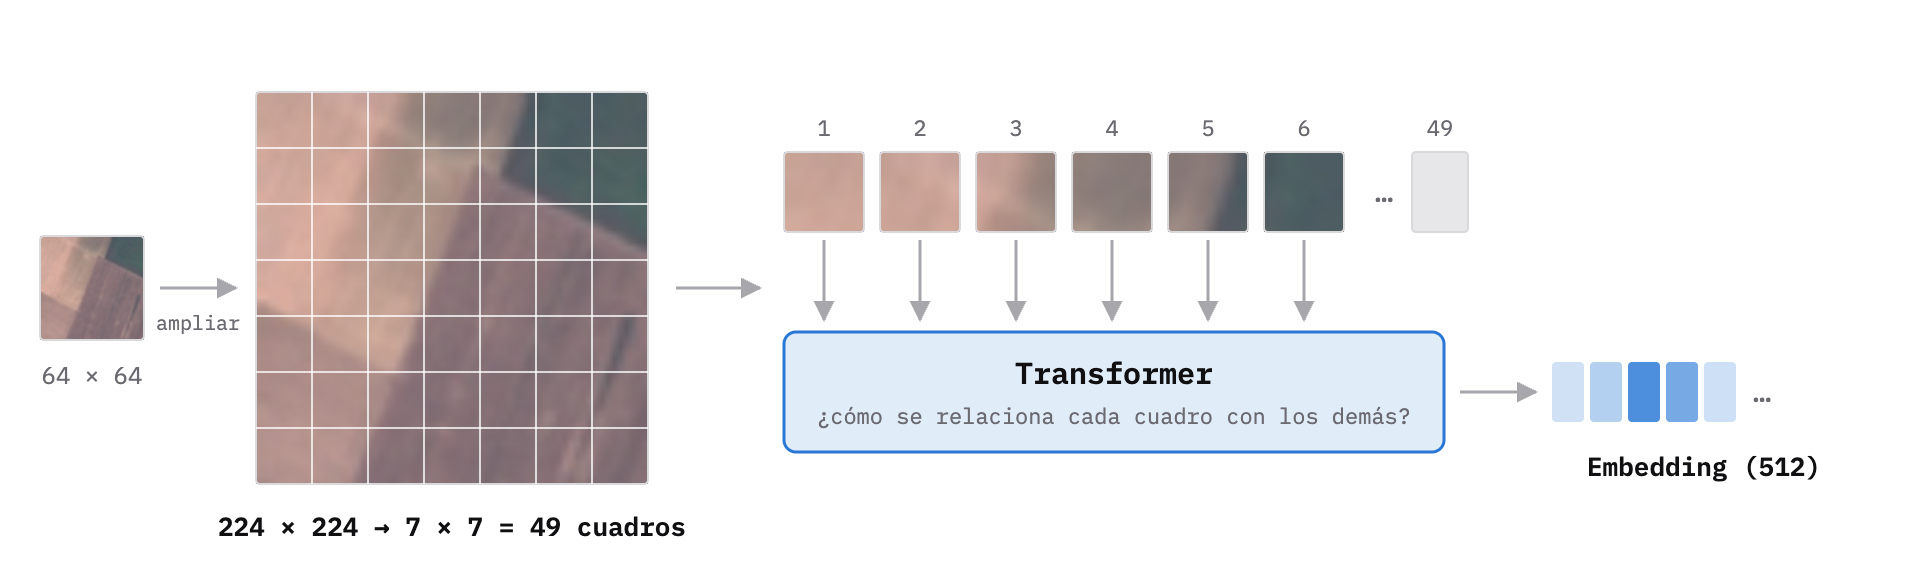

<sub>Cómo ve una imagen el *Vision Transformer*: la amplía a 224 × 224, la corta en 49 cuadros y analiza cómo se relacionan.</sub>

Definimos dos funciones: una convierte imágenes en vectores y la otra convierte textos en vectores. En ambas **normalizamos** el resultado para que cada vector tenga longitud 1; así, el producto punto entre dos vectores es directamente su **similitud coseno** (1 = idénticos, 0 = sin relación).

> **📖 Definición · Similitud coseno**
>
> La **similitud coseno** mide qué tan parecida es la **dirección** de dos vectores, sin importar su longitud:
>
> $$\text{sim}(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a} \cdot \mathbf{b}}{\lVert \mathbf{a} \rVert \, \lVert \mathbf{b} \rVert} = \cos \theta$$
>
> donde $\theta$ es el ángulo entre los vectores. Vale **1** si apuntan en la misma dirección, **0** si son perpendiculares (sin relación) y **−1** si apuntan en direcciones opuestas.
>
> Si **normalizamos** los vectores para que tengan longitud 1, el denominador vale 1 y la similitud es simplemente el **producto punto** $\mathbf{a} \cdot \mathbf{b}$. Por eso, con una sola multiplicación de matrices (`X @ X.T`) obtenemos la similitud entre todos los pares de imágenes a la vez.

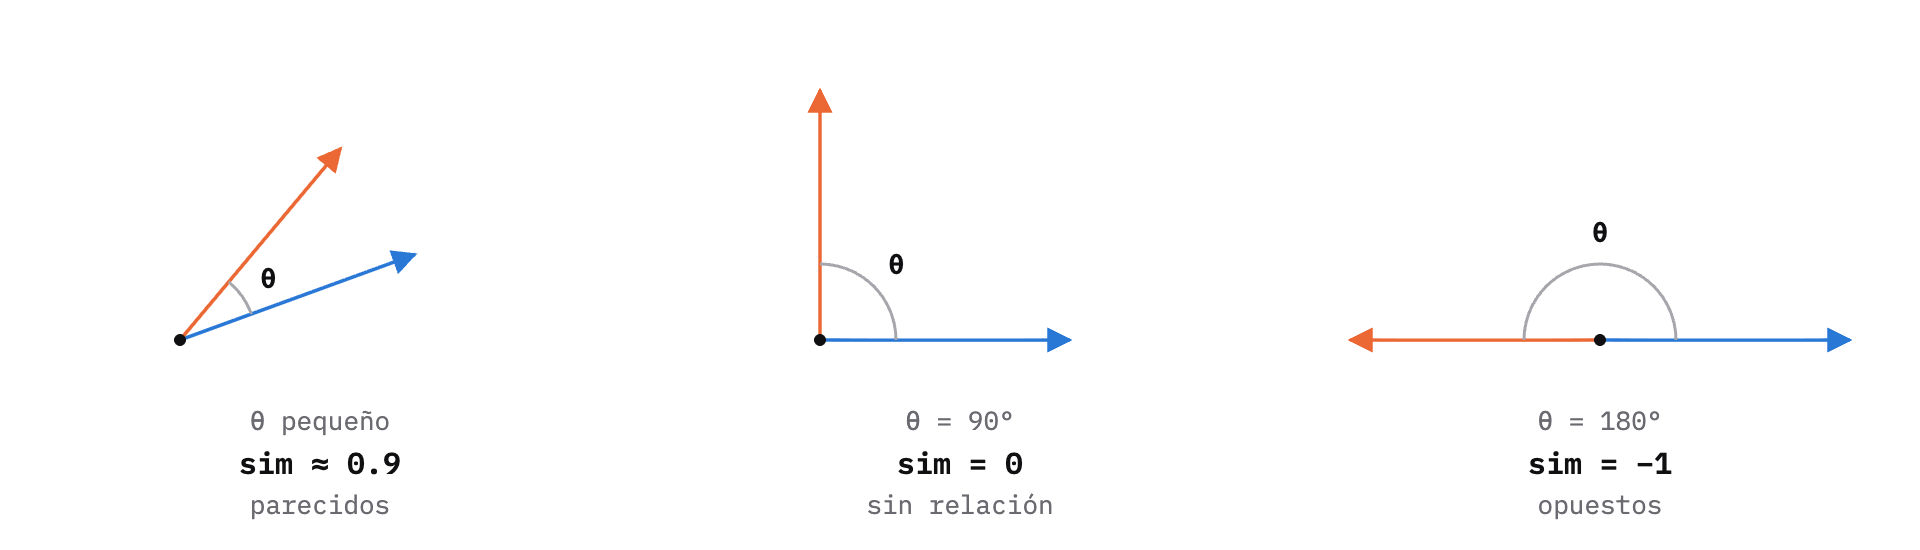

<sub>La similitud coseno solo depende del ángulo entre los vectores (azul y naranja), no de su longitud.</sub>

In [11]:
def _a_tensor(salida):
    # Según la versión de transformers, se devuelve un tensor o un objeto con el tensor en pooler_output
    return salida if torch.is_tensor(salida) else salida.pooler_output


@torch.no_grad()  # no vamos a entrenar, así que no necesitamos calcular gradientes
def embeddings_de_imagenes(rutas, lote=64):
    vectores = []
    for i in range(0, len(rutas), lote):
        imagenes = [Image.open(r).convert("RGB") for r in rutas[i:i + lote]]
        entrada = procesador(images=imagenes, return_tensors="pt").to(DISPOSITIVO)
        v = _a_tensor(modelo.get_image_features(**entrada))
        vectores.append(torch.nn.functional.normalize(v, dim=-1).cpu().numpy())
    return np.concatenate(vectores)


@torch.no_grad()
def embeddings_de_textos(textos):
    entrada = procesador(text=textos, return_tensors="pt", padding=True).to(DISPOSITIVO)
    v = _a_tensor(modelo.get_text_features(**entrada))
    return torch.nn.functional.normalize(v, dim=-1).cpu().numpy()

In [12]:
# Calculamos el embedding de las 2,000 imágenes (es el paso más lento del taller)
inicio = time.time()
X = embeddings_de_imagenes(df["ruta"].tolist())
print(f"Embeddings: {X.shape} en {time.time() - inicio:.0f} segundos")

Embeddings: (2000, 512) en 49 segundos


Cada imagen quedó resumida en **512 números** en lugar de 12,288: una reducción de 24 veces. Veamos cómo luce uno de esos vectores:

In [13]:
print(f"Primeros 8 valores del embedding de la imagen 0 ({df.loc[0, 'clase_es']}):")
print(np.round(X[0, :8], 3))
print(f"\nLongitud del vector (norma): {np.linalg.norm(X[0]):.3f}")

Primeros 8 valores del embedding de la imagen 0 (Cultivo anual):
[ 0.009 -0.     0.024 -0.033  0.034 -0.035  0.04   0.055]

Longitud del vector (norma): 1.000


Los números individuales **no tienen un significado que podamos interpretar** (no hay una "coordenada de bosque"). Lo que importa es la **distancia entre vectores**. Comprobémoslo con la similitud coseno, que, como los vectores están normalizados, es simplemente el producto punto:

In [14]:
# Similitud promedio entre imágenes de la misma clase y de clases distintas
S = X @ X.T                    # matriz de similitud: 2,000 × 2,000
y_clase = df["clase"].to_numpy()
misma = y_clase[:, None] == y_clase[None, :]
np.fill_diagonal(misma, False)  # excluimos la similitud de cada imagen consigo misma
distinta = y_clase[:, None] != y_clase[None, :]

print(f"Similitud promedio, misma clase:   {S[misma].mean():.3f}")
print(f"Similitud promedio, clase distinta: {S[distinta].mean():.3f}")

Similitud promedio, misma clase:   0.889
Similitud promedio, clase distinta: 0.809


In [15]:
# Similitud promedio entre cada par de clases (10 × 10)
sim_clases = pd.DataFrame(index=CLASES, columns=CLASES, dtype=float)
for a in CLASES:
    for b in CLASES:
        bloque = S[np.ix_(y_clase == a, y_clase == b)]
        if a == b:
            bloque = bloque[~np.eye(len(bloque), dtype=bool)]  # sin la diagonal
        sim_clases.loc[a, b] = bloque.mean()

etiquetas = [ES[c] for c in CLASES]
fig = go.Figure(go.Heatmap(
    z=sim_clases.to_numpy(), x=etiquetas, y=etiquetas,
    colorscale=ESCALA_AZUL, colorbar=dict(title="Similitud"),
    text=sim_clases.to_numpy(), texttemplate="%{text:.2f}", textfont=dict(size=10),
    hovertemplate="%{y} ↔ %{x}<br>Similitud promedio: %{z:.3f}<extra></extra>",
))
fig.update_layout(title="Similitud coseno promedio entre clases", width=720, height=620)
fig.update_yaxes(autorange="reversed", showgrid=False)  # primera clase arriba, como en una tabla
fig.update_xaxes(tickangle=-40, showgrid=False)
fig.show()

**🔍 ¿Qué observamos?**

- **En cada renglón, el valor más alto está en la diagonal:** en promedio, una imagen se parece más a las de su propia clase (0.889) que a las de otras clases (0.809). CLIP nunca vio nuestras etiquetas, así que esa organización la aprendió por su cuenta.
- **Todas las similitudes son altas (entre 0.68 y 0.93).** Los embeddings de CLIP ocupan una región estrecha del espacio, así que el valor absoluto dice poco. Lo que importa es la **comparación relativa**: qué imagen está *más* cerca que otra.
- **Bosque y Mar o lago se parecen mucho (0.89):** ambas son superficies oscuras y uniformes, con pocos detalles. En cambio, las zonas urbanas (Industrial, Residencial) son las más lejanas del agua (0.68 y 0.69).

---

## 3. Un mapa del dataset: PCA y UMAP

No podemos dibujar 512 dimensiones, pero sí podemos **proyectarlas a 2** y ver si las clases se separan solas. Es importante notar que **CLIP nunca vio nuestras etiquetas**: si las clases aparecen agrupadas, es porque el modelo aprendió por su cuenta a distinguir esos contenidos.

Comparamos dos técnicas:

- **PCA**: una proyección **lineal** que conserva las direcciones de mayor varianza.
- **UMAP**: una técnica **no lineal** que intenta conservar quién es vecino de quién. Es mejor para visualizar grupos, pero las distancias entre grupos lejanos no tienen un significado preciso.

> **📖 Definición · Reducción de dimensionalidad**
>
> Reducir la dimensionalidad es **representar datos de muchas columnas con muy pocas, perdiendo la menor información posible**. Se usa para visualizar (2 o 3 dimensiones se pueden dibujar), para comprimir datos o para eliminar ruido antes de entrenar un modelo. El precio es que siempre se pierde algo: ninguna proyección a 2 dimensiones conserva todo lo que hay en 512.

> **⚙️ Cómo funciona · PCA**
>
> **PCA** (*Principal Component Analysis*, análisis de componentes principales) busca las direcciones en las que los datos **varían más** y proyecta los datos sobre ellas. El proceso, de manera sencilla:
>
> 1. **Centrar** los datos: restar a cada columna su promedio.
> 2. Encontrar la dirección en la que los datos están **más dispersos**: ese es el **primer componente principal**.
> 3. Encontrar la siguiente dirección de mayor dispersión, **perpendicular** a la anterior: el **segundo componente**. Y así sucesivamente.
> 4. **Proyectar** cada dato sobre los primeros componentes; en nuestro caso, sobre los dos primeros.
>
> La **varianza explicada** indica qué porcentaje de la dispersión total conservan los componentes elegidos. Como PCA es una proyección **lineal** (como la sombra de un objeto sobre una pared), no puede "desenrollar" estructuras curvas en los datos.

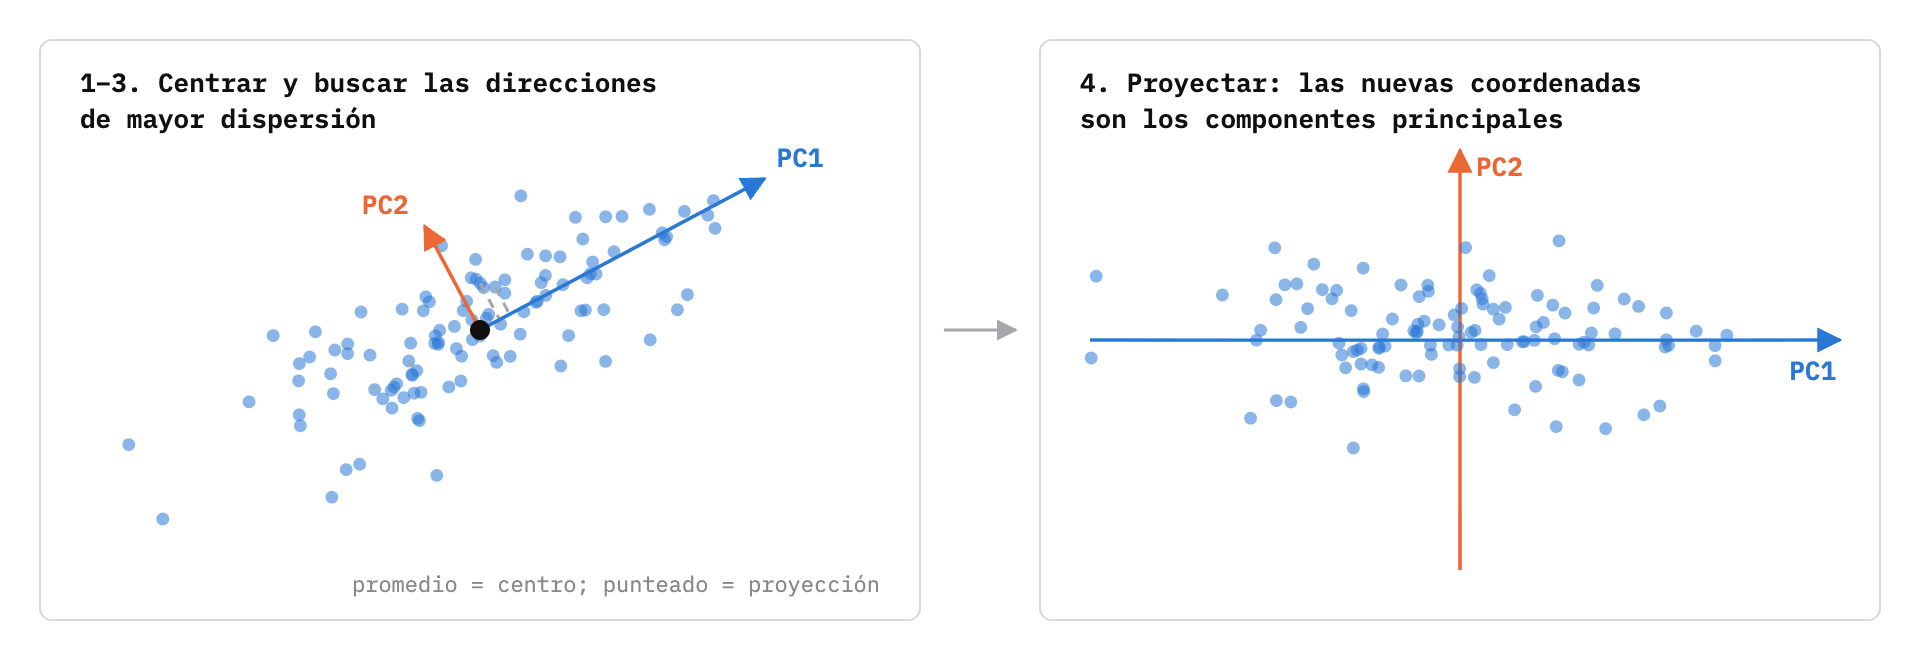

<sub>PCA en dos pasos: encontrar las direcciones de mayor dispersión (PC1, PC2) y usarlas como los nuevos ejes.</sub>

> **⚙️ Cómo funciona · UMAP**
>
> **UMAP** (*Uniform Manifold Approximation and Projection*) no busca direcciones de varianza: busca **conservar quién es vecino de quién**. El proceso, de manera sencilla:
>
> 1. En el espacio original de 512 dimensiones, encuentra los **vecinos más cercanos** de cada punto y construye una red (un grafo) que los conecta.
> 2. Coloca los puntos al azar en un plano de 2 dimensiones.
> 3. Mueve los puntos poco a poco: **acerca** los que estaban conectados en la red y **aleja** los que no lo estaban, hasta que la red en 2D se parezca lo más posible a la original.
>
> Sus dos parámetros principales son `n_neighbors` (cuántos vecinos considera: valores bajos resaltan detalles locales y valores altos, la estructura global) y `min_dist` (qué tan apretados pueden quedar los puntos).

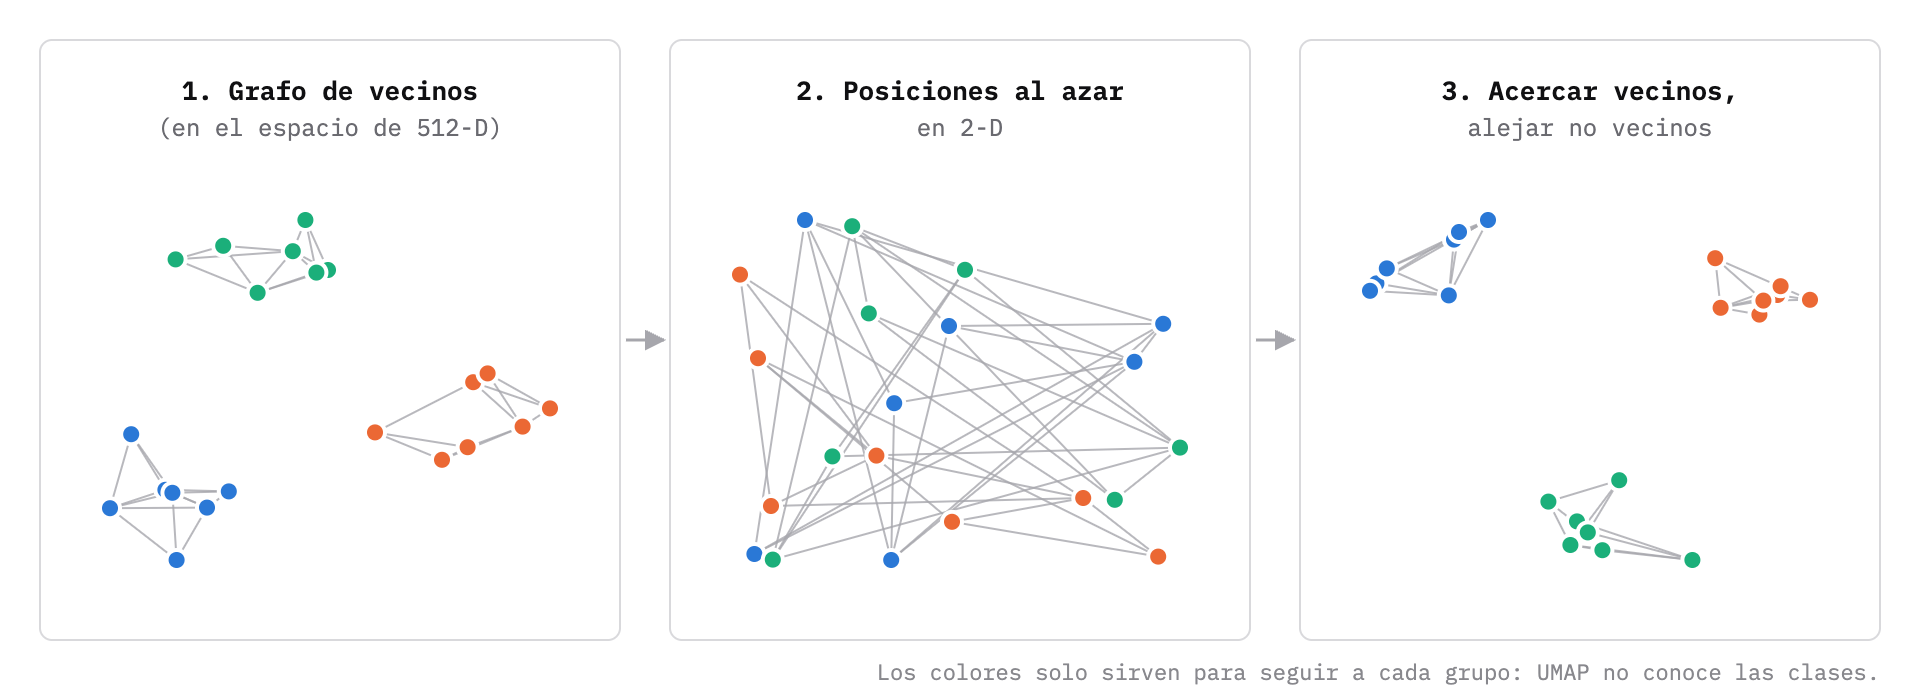

<sub>UMAP en tres pasos: el grafo de vecinos se construye en el espacio original y luego se busca un acomodo en 2-D que lo respete.</sub>

> **⚠️ Cuidado · Cómo leer un mapa de UMAP**
>
> En un mapa de UMAP, el **tamaño** de un grupo y la **distancia entre grupos lejanos** no tienen un significado preciso. Lo confiable es qué puntos quedan juntos. Una técnica parecida y muy usada es **t-SNE**.

In [16]:
# Proyección a 2 dimensiones con cada técnica
pca = PCA(n_components=2, random_state=SEMILLA)
X_pca = pca.fit_transform(X)
print(f"Varianza explicada por los 2 componentes de PCA: {pca.explained_variance_ratio_.sum() * 100:.1f}%")

reductor = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEMILLA)
X_umap = reductor.fit_transform(X)
print("UMAP listo")

Varianza explicada por los 2 componentes de PCA: 41.7%


UMAP listo


Con 10 clases, diez colores distintos serían difíciles de distinguir (sobre todo para personas con daltonismo). En lugar de eso, **resaltamos tres clases** y dejamos las demás en gris como contexto:

In [17]:
# Tres clases resaltadas; el resto queda en gris
RESALTAR = {"Forest": AZUL, "Industrial": NARANJA, "SeaLake": VERDE_AGUA}

# Texto que aparece al pasar el cursor sobre cada punto: clase y nombre del archivo
df["archivo"] = df["ruta"].map(lambda r: Path(r).name)
HOVER_PUNTO = "<b>%{customdata[0]}</b><br>%{customdata[1]}<extra></extra>"

fig = make_subplots(rows=1, cols=2, subplot_titles=["PCA (lineal)", "UMAP (no lineal)"], horizontal_spacing=0.05)
for col, coords in [(1, X_pca), (2, X_umap)]:
    grupos = [("Otras 7 clases", ~df["clase"].isin(RESALTAR).to_numpy(), GRIS, 5)]
    grupos += [(ES[c], (df["clase"] == c).to_numpy(), color, 7) for c, color in RESALTAR.items()]
    for nombre, m, color, tam in grupos:
        fig.add_trace(go.Scattergl(
            x=coords[m, 0], y=coords[m, 1], mode="markers", name=nombre,
            legendgroup=nombre, showlegend=(col == 1),  # una sola entrada de leyenda por grupo
            marker=dict(size=tam, color=color, opacity=0.55 if color == GRIS else 0.85,
                        line=dict(width=0.5, color="white")),
            customdata=df.loc[m, ["clase_es", "archivo"]].to_numpy(), hovertemplate=HOVER_PUNTO,
        ), row=1, col=col)
fig.update_xaxes(showticklabels=False, showgrid=False, ticks="")
fig.update_yaxes(showticklabels=False, showgrid=False, ticks="")
fig.update_layout(title="Las 2,000 imágenes proyectadas a 2 dimensiones", width=1000, height=500,
                  legend=dict(orientation="h", y=-0.05, x=0.5, xanchor="center"))
fig.show()

Ahora veamos **todas** las clases con UMAP, una por panel (lo que en visualización se llama *small multiples*):

In [18]:
# Un panel por clase: la clase en azul y el resto del dataset en gris
fig = make_subplots(rows=2, cols=5, subplot_titles=[ES[c] for c in CLASES],
                    shared_xaxes=True, shared_yaxes=True, horizontal_spacing=0.02, vertical_spacing=0.1)
for k, clase in enumerate(CLASES):
    fila, col = k // 5 + 1, k % 5 + 1
    m = (df["clase"] == clase).to_numpy()
    fig.add_trace(go.Scattergl(x=X_umap[~m, 0], y=X_umap[~m, 1], mode="markers", showlegend=False,
                               marker=dict(size=3, color=GRIS, opacity=0.45), hoverinfo="skip"), row=fila, col=col)
    fig.add_trace(go.Scattergl(x=X_umap[m, 0], y=X_umap[m, 1], mode="markers", showlegend=False,
                               marker=dict(size=4, color=AZUL),
                               customdata=df.loc[m, ["clase_es", "archivo"]].to_numpy(), hovertemplate=HOVER_PUNTO),
                  row=fila, col=col)
fig.update_xaxes(showticklabels=False, showgrid=False, ticks="")
fig.update_yaxes(showticklabels=False, showgrid=False, ticks="")
fig.update_annotations(font=dict(size=12, color="#0b0b0b"))  # títulos de cada panel
fig.update_layout(title="Mapa UMAP: ¿dónde queda cada clase?", width=1100, height=520)
fig.show()

**🔍 ¿Qué observamos?**

- **PCA** con solo 2 componentes conserva el 41.7% de la varianza. Industrial se separa hacia un extremo, pero Bosque y Mar o lago quedan encimados en la misma franja.
- **UMAP** separa mucho mejor los grupos. Industrial y Residencial forman "islas" bien definidas; Bosque y Mar o lago quedan juntos, pero cada uno en su propia zona.
- **Autopista, Río y Pastizal quedan dispersos** en el centro del mapa, mezclados con otras clases. Esto nos anticipa dónde se va a equivocar cualquier modelo que construyamos con estos embeddings.

---

## 4. Buscador de imágenes similares

Con los embeddings, un buscador es sorprendentemente sencillo: **dada una imagen, ordenamos todas las demás por su similitud coseno** y devolvemos las más parecidas. Esto es lo que hacen, a gran escala, la búsqueda por imagen de Google o la función "productos similares" de una tienda en línea.

> **📖 Definición · Búsqueda por vecinos más cercanos**
>
> Lo que vamos a construir se llama **búsqueda de vecinos más cercanos** (*nearest neighbor search*): dado un vector de consulta, encontrar los vectores del dataset más similares a él. Con 2,000 imágenes podemos compararlo contra todas, lo cual se conoce como **búsqueda exacta**. Con millones de vectores eso sería muy lento, así que se usan índices de **búsqueda aproximada**, que sacrifican un poco de precisión a cambio de mucha velocidad. Es lo que hacen las **bases de datos vectoriales**, las mismas que usan los sistemas de IA que buscan información en documentos.

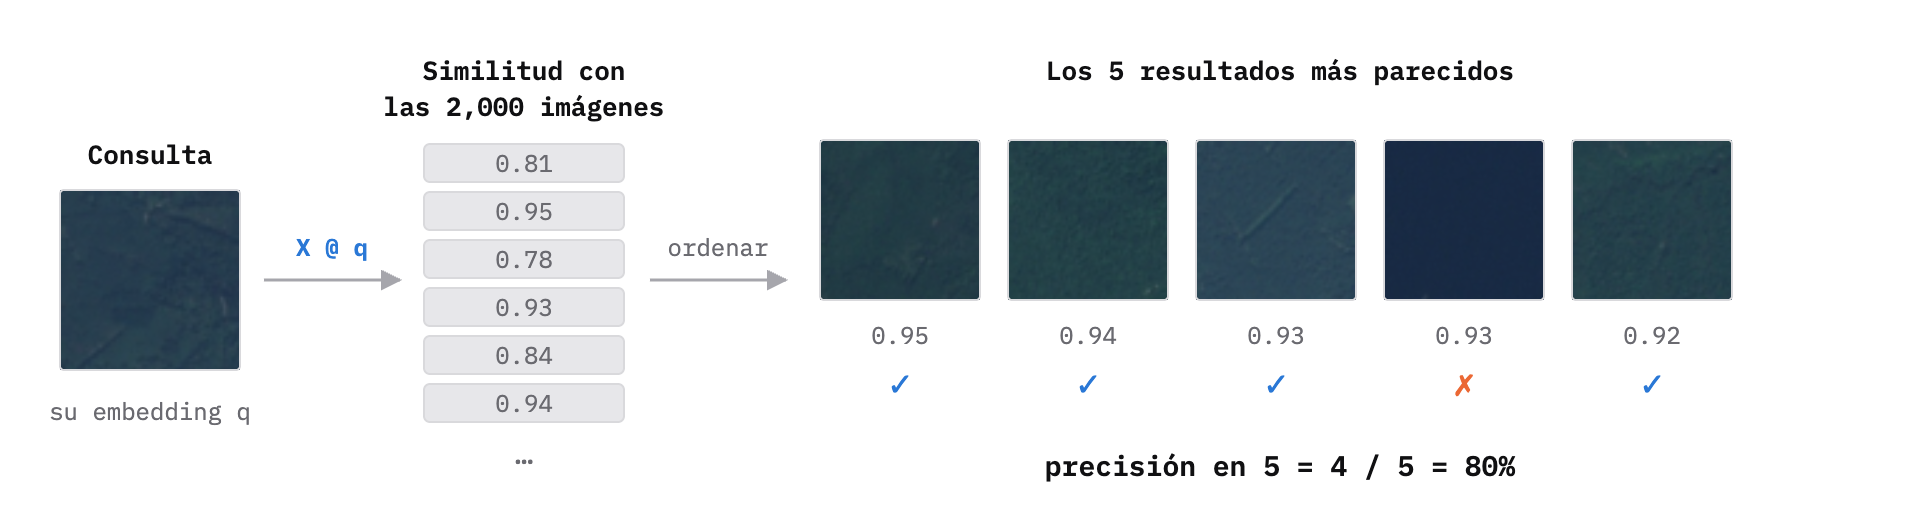

<sub>El buscador completo: comparar, ordenar y quedarse con los primeros. La precisión en 5 cuenta cuántos son de la clase correcta.</sub>

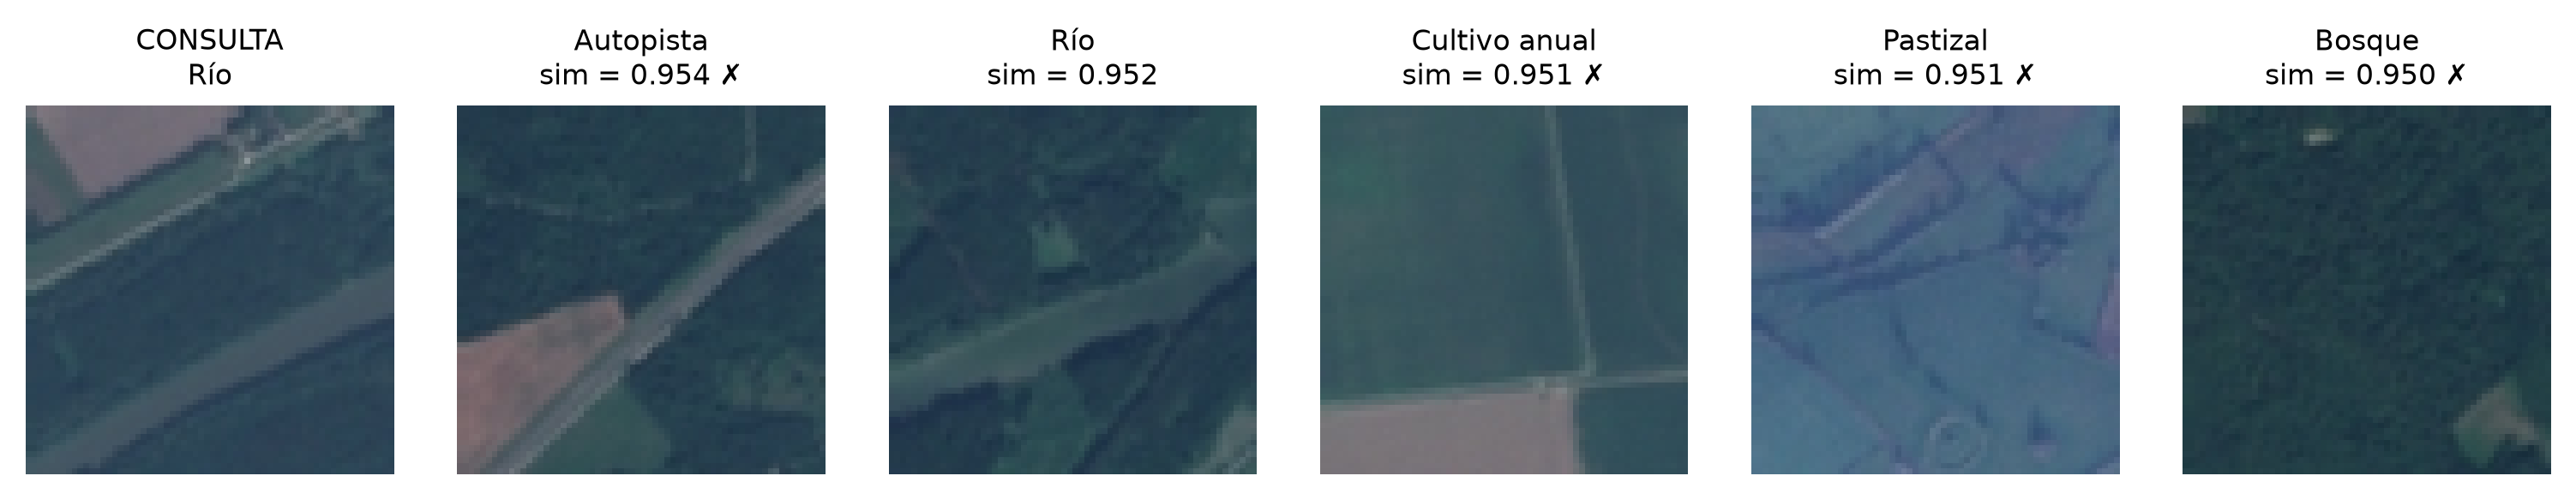

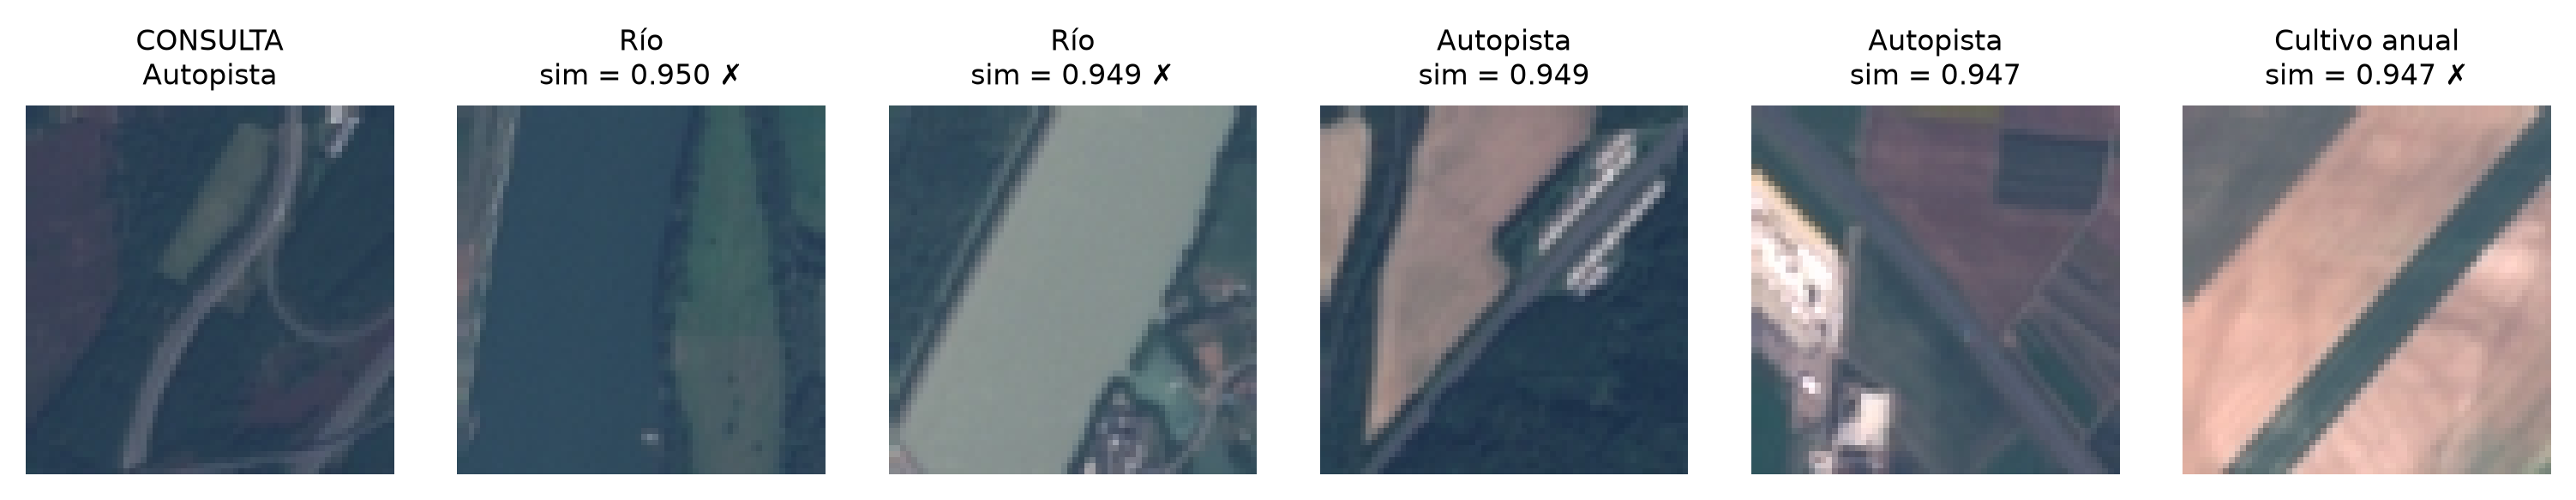

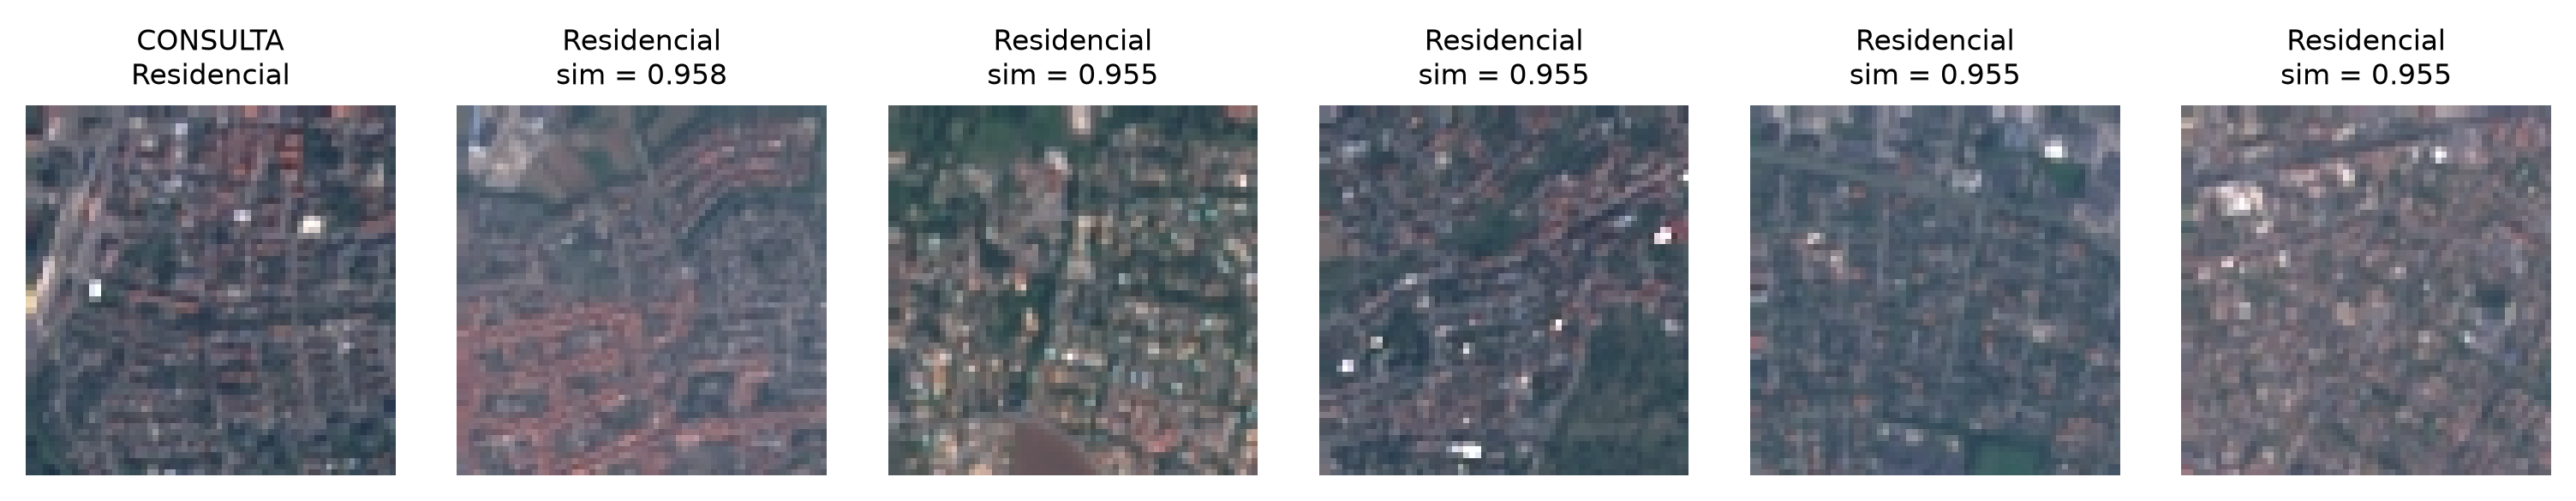

In [19]:
def buscar_similares(i, k=5):
    # Devuelve los índices y similitudes de las k imágenes más parecidas a la imagen i
    similitudes = X @ X[i]
    similitudes[i] = -np.inf                 # excluimos la propia imagen
    vecinos = np.argsort(-similitudes)[:k]   # orden descendente
    return vecinos, similitudes[vecinos]


def mostrar_busqueda(i, k=5):
    vecinos, sims = buscar_similares(i, k)
    rutas = [df.loc[i, "ruta"]] + df.loc[vecinos, "ruta"].tolist()
    titulos = [f"CONSULTA\n{df.loc[i, 'clase_es']}"] + [
        f"{df.loc[j, 'clase_es']}\nsim = {s:.3f}" + ("" if df.loc[j, "clase"] == df.loc[i, "clase"] else " ✗")
        for j, s in zip(vecinos, sims)
    ]
    mostrar_imagenes(rutas, titulos, columnas=k + 1, tam=1.7)


# Una consulta de ejemplo por cada una de tres clases
for clase in ["River", "Highway", "Residential"]:
    mostrar_busqueda(df.index[df["clase"] == clase][0])

La marca ✗ indica un resultado de otra clase. Para medir el buscador en todo el dataset, usamos la **precisión en k** (*precision@k*): de los k resultados, ¿qué proporción es de la misma clase que la consulta?

> **📖 Definición · Precisión en k, con un ejemplo**
>
> Si buscamos las 5 imágenes más parecidas a un bosque y 4 de ellas son bosques, la precisión en 5 de esa consulta es 4 / 5 = **80%**. La precisión en k del buscador es el **promedio** sobre todas las consultas. Es una métrica estándar para evaluar buscadores y sistemas de recomendación, porque mide la calidad de lo que la persona realmente ve: los primeros resultados.

In [20]:
# Precisión en 5: promedio sobre las 2,000 consultas
K = 5
S_sin_diag = S.copy()
np.fill_diagonal(S_sin_diag, -np.inf)
top_k = np.argsort(-S_sin_diag, axis=1)[:, :K]
aciertos = (y_clase[top_k] == y_clase[:, None])

precision_k = pd.Series(aciertos.mean(axis=1), index=df["clase_es"]).groupby(level=0).mean().sort_values()
print(f"Precisión en {K} global: {aciertos.mean() * 100:.1f}%  (al azar sería 10%)")

fig = go.Figure(go.Bar(
    x=precision_k.values * 100, y=precision_k.index, orientation="h", marker_color=AZUL,
    text=[f"{v:.0f}%" for v in precision_k.values * 100], textposition="outside",
    hovertemplate="%{y}<br>Precisión en 5: %{x:.1f}%<extra></extra>",
))
fig.update_layout(title=f"Precisión en {K} del buscador, por clase", width=720, height=430,
                  xaxis=dict(title="Resultados de la misma clase (%)", range=[0, 105]),
                  yaxis=dict(showgrid=False))
fig.show()

Precisión en 5 global: 78.8%  (al azar sería 10%)


**🔍 ¿Qué observamos?**

- **El buscador funciona sin haber entrenado nada:** en promedio, el 78.8% de los 5 resultados son de la misma clase que la consulta, contra 10% si eligiéramos al azar.
- **Las clases con textura uniforme son las más fáciles** (Bosque, 94%). Las más difíciles son **Autopista (61%) y Río (66%)**. En el ejemplo de arriba, de los 5 resultados para la consulta de un río solo uno es río; los demás son una autopista, un cultivo, un pastizal y un bosque: a 10 metros por pixel, un río y una carretera son, ambos, **una franja que cruza un terreno verde**.
- La zona Residencial, en cambio, devuelve 5 de 5 resultados correctos: su textura de calles y techos es muy característica.

### ✏️ Ejercicio 1

Elige una imagen al azar y busca sus 8 imágenes más parecidas. ¿Los errores del buscador tienen sentido? Por ejemplo, ¿confunde clases que también te costaría distinguir a ti?

*Pista:* usa `mostrar_busqueda(i, k)` con un índice `i` entre 0 y 1,999.

In [21]:
# Tu código aquí

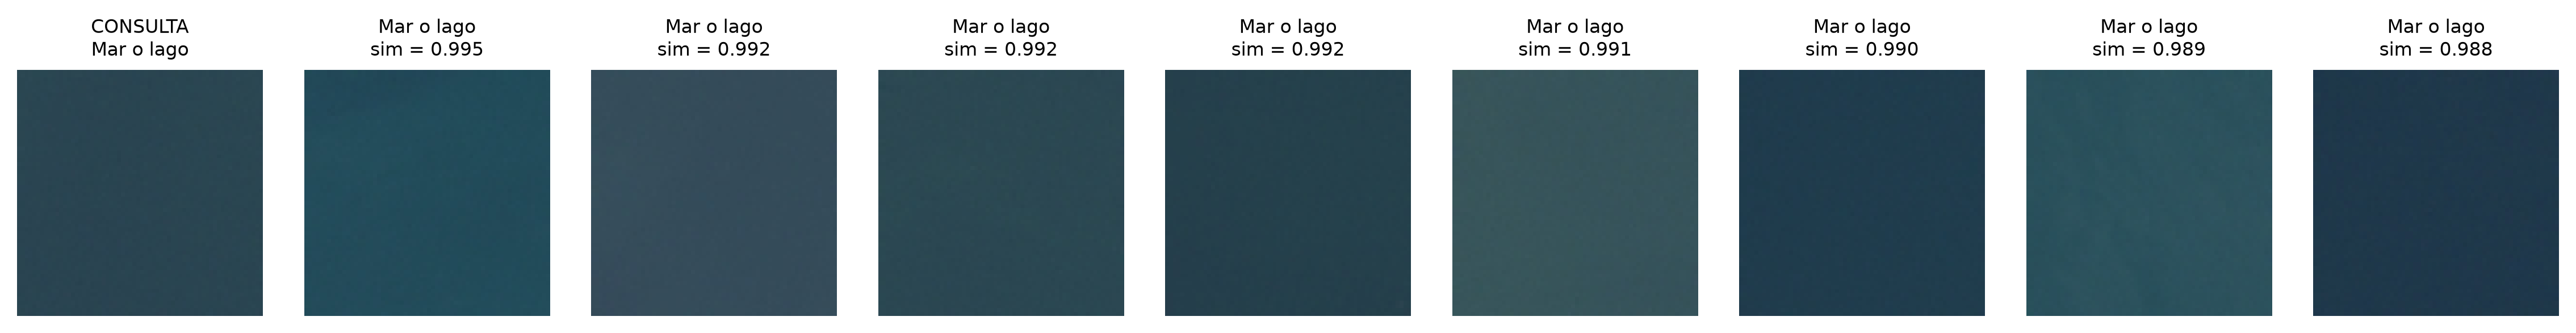

In [22]:
# Solución propuesta: una consulta aleatoria (cambia la semilla para ver otras)
rng = np.random.default_rng(7)
mostrar_busqueda(int(rng.integers(len(df))), k=8)

---

## 5. Clasificación *zero-shot* con texto

Como CLIP pone imágenes y textos en el mismo espacio, podemos **clasificar sin entrenar**:

1. Escribimos una frase por clase, por ejemplo *"a satellite photo of a forest"*.
2. Calculamos el embedding de cada frase.
3. A cada imagen le asignamos la clase cuya frase sea **más similar**.

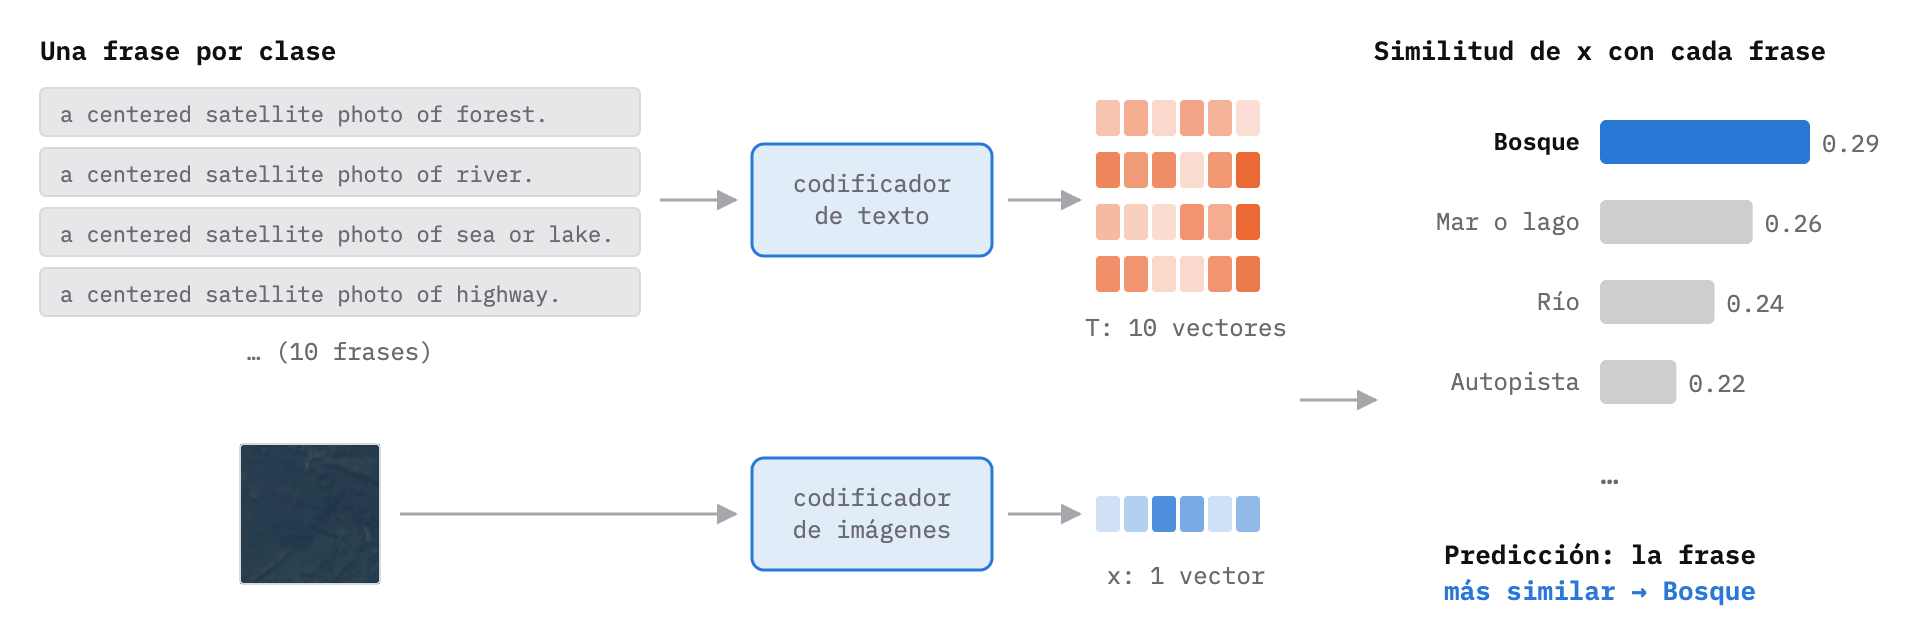

<sub>Clasificación *zero-shot*: el *embedding* de la imagen se compara con el de una frase por clase, y gana la más parecida.</sub>

A esto se le llama ***zero-shot***: cero ejemplos etiquetados. Para comparar de forma justa con el bloque 6, separamos desde ahora un **conjunto de prueba** (50 imágenes por clase) que usaremos para evaluar todos los métodos.

> **📖 Definición · *Zero-shot*, *few-shot* y entrenamiento supervisado**
>
> Estos términos describen **cuántos ejemplos etiquetados** necesita un método para resolver una tarea nueva:
>
> | Término | Ejemplos etiquetados | En este taller |
> |---|---|---|
> | ***Zero-shot*** | Ninguno: solo una descripción de cada clase | Bloque 5: clasificar con frases |
> | ***Few-shot*** | Unos cuantos por clase (1, 5, 10…) | Bloque 6.1: curva de aprendizaje |
> | **Entrenamiento supervisado** | Muchos por clase | Bloque 6: 150 por clase |

> **📖 Definición · Conjuntos de entrenamiento y de prueba**
>
> Un modelo se evalúa con datos que **no vio** durante su ajuste; de lo contrario, mediríamos qué tan bien memoriza, no qué tan bien generaliza. Por eso separamos:
>
> - **Entrenamiento:** imágenes con las que el modelo aprende.
> - **Prueba:** imágenes que se guardan aparte y se usan **solo para medir** el resultado final.
>
> La división es **estratificada** (`stratify=y`): cada clase conserva la misma proporción en ambos conjuntos, en nuestro caso 150 y 50 imágenes por clase.

In [23]:
# Etiquetas numéricas y división estratificada: 150 imágenes por clase para entrenar, 50 para probar
y = df["clase"].map({c: i for i, c in enumerate(CLASES)}).to_numpy()
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.25, stratify=y, random_state=SEMILLA)
X_train, X_test, y_train, y_test = X[idx_train], X[idx_test], y[idx_train], y[idx_test]
print(f"Entrenamiento: {len(idx_train)} | Prueba: {len(idx_test)}")

Entrenamiento: 1500 | Prueba: 500


CLIP se entrenó principalmente con texto en inglés, así que las frases van en inglés. Probemos tres formas de escribirlas: solo el nombre de la clase, y dos plantillas más descriptivas. Algunos nombres los reescribimos para que suenen más naturales (por ejemplo, `SeaLake` como *"sea or lake"*).

> **📖 Definición · *Prompt***
>
> Un ***prompt*** es el texto que le damos a un modelo para indicarle qué queremos. Aquí, cada *prompt* es la frase que describe una clase, y una **plantilla** es un *prompt* con un hueco (`{}`) que se rellena con el nombre de cada clase. Ajustar estas frases para obtener mejores resultados, sin cambiar el modelo, se conoce como **ingeniería de *prompts***.

In [24]:
# Nombre "natural" de cada clase en inglés
NOMBRE_EN = {
    "AnnualCrop": "annual crop land",
    "Forest": "forest",
    "HerbaceousVegetation": "herbaceous vegetation",
    "Highway": "highway",
    "Industrial": "industrial buildings",
    "Pasture": "pasture",
    "PermanentCrop": "permanent crop land",
    "Residential": "residential buildings",
    "River": "river",
    "SeaLake": "sea or lake",
}


def zero_shot(plantilla, X_eval):
    # Clasifica cada imagen con la clase cuya frase sea más similar
    frases = [plantilla.format(NOMBRE_EN[c]) for c in CLASES]
    T = embeddings_de_textos(frases)
    return (X_eval @ T.T).argmax(axis=1)


PLANTILLAS = ["{}", "a satellite photo of {}.", "a centered satellite photo of {}."]
resultados_zs = pd.DataFrame({
    "plantilla": PLANTILLAS,
    "exactitud": [accuracy_score(y_test, zero_shot(p, X_test)) for p in PLANTILLAS],
})
resultados_zs

,plantilla,exactitud
0,{},0.366
1,a satellite photo of {}.,0.420
2,a centered satellite photo of {}.,0.448


**🔍 ¿Qué observamos?**

- **La forma de escribir la frase importa:** sin cambiar el modelo ni los datos, la exactitud pasa de 36.6% (solo el nombre) a 44.8% (*"a centered satellite photo of …"*). Decirle a CLIP que es una foto satelital le da contexto. A esto se le conoce como **ingeniería de *prompts***.
- Aun así, **44.8% es poco para un sistema real:** es mucho mejor que el azar (10%), pero se equivoca en más de la mitad de las imágenes.

Veamos con la **matriz de confusión** en qué se equivoca la mejor plantilla. Cada renglón es la clase real y cada columna la clase predicha; la diagonal son los aciertos.

> **📖 Definición · Métricas de clasificación**
>
> - **Exactitud** (*accuracy*): proporción de imágenes clasificadas correctamente, sobre el total.
> - **Matriz de confusión:** tabla que cruza la clase real con la predicha. La diagonal son los aciertos, y cada celda fuera de la diagonal indica **qué se confunde con qué**.
> - **Recall** (sensibilidad) de una clase: de las imágenes que **realmente** son de esa clase, ¿qué proporción reconoció el modelo? Se lee **por renglón**: aciertos de la clase ÷ total de su renglón.
> - **Precisión** de una clase: de las imágenes que el modelo **dijo** que son de esa clase, ¿qué proporción lo es? Se lee **por columna**.
>
> Con clases balanceadas, la exactitud es un buen resumen. Pero siempre conviene revisar la matriz de confusión: dos modelos con la misma exactitud pueden equivocarse de formas muy distintas.

In [25]:
MEJOR_PLANTILLA = resultados_zs.loc[resultados_zs["exactitud"].idxmax(), "plantilla"]
pred_zs = zero_shot(MEJOR_PLANTILLA, X_test)
acc_zs = accuracy_score(y_test, pred_zs)


def graficar_confusion(y_real, y_pred, titulo):
    cm = confusion_matrix(y_real, y_pred, labels=range(10))
    etiquetas = [ES[c] for c in CLASES]
    texto = np.where(cm > 0, cm.astype(str), "")  # ocultamos los ceros para que se lea mejor
    fig = go.Figure(go.Heatmap(
        z=cm, x=etiquetas, y=etiquetas, colorscale=ESCALA_AZUL, showscale=False,
        text=texto, texttemplate="%{text}", textfont=dict(size=11),
        hovertemplate="Real: %{y}<br>Predicha: %{x}<br>Imágenes: %{z}<extra></extra>",
    ))
    fig.update_layout(title=titulo, width=680, height=620,
                      xaxis=dict(title="Clase predicha", tickangle=-40, showgrid=False),
                      yaxis=dict(title="Clase real", autorange="reversed", showgrid=False))
    fig.show()
    return cm


cm_zs = graficar_confusion(y_test, pred_zs, f"Zero-shot: '{MEJOR_PLANTILLA}'<br><sup>exactitud = {acc_zs * 100:.1f}%</sup>")

In [26]:
# Recall por clase: de las imágenes de cada clase, ¿cuántas reconoció?
recall_zs = pd.Series(cm_zs.diagonal() / cm_zs.sum(axis=1), index=[ES[c] for c in CLASES])
recall_zs.sort_values(ascending=False).map("{:.0%}".format).to_frame("recall zero-shot")

,recall zero-shot
Industrial,88%
Residencial,70%
Cultivo anual,66%
Bosque,66%
Autopista,56%
Mar o lago,56%
Pastizal,36%
Río,10%
Vegetación herbácea,0%
Cultivo permanente,0%


**🔍 ¿Qué observamos?**

- **Industrial tiene el mejor recall (88%), pero porque CLIP lo predice demasiado:** la columna Industrial recibe 127 predicciones, cuando solo hay 50 imágenes industriales. Muchos cultivos permanentes (21), ríos (17) y zonas residenciales (15) terminan ahí.
- **Vegetación herbácea y Cultivo permanente tienen 0% de recall:** CLIP nunca las predice (sus columnas están vacías). Sus nombres son términos técnicos que casi no aparecen en los textos de internet con los que se entrenó el modelo. La vegetación herbácea se confunde sobre todo con Bosque (27 de 50).
- **Río solo tiene 10% de recall**, por la misma razón que vimos en el buscador.

### ✏️ Ejercicio 2

Escribe tu propia plantilla, o cambia los nombres en `NOMBRE_EN`, e intenta superar la exactitud de la mejor plantilla. Fíjate sobre todo en las clases con recall bajo: ¿cómo describirías una imagen de esa clase a alguien que no la ve?

*Pista:* `accuracy_score(y_test, zero_shot("tu plantilla con {}", X_test))`

In [27]:
# Tu código aquí

In [28]:
# Solución propuesta: cambiar los nombres técnicos de las dos clases con recall de 0%
# por palabras más comunes en internet, que es de donde aprendió CLIP
NOMBRE_EN_ORIGINAL = NOMBRE_EN.copy()
cambios = {"HerbaceousVegetation": "shrubland", "PermanentCrop": "an orchard or vineyard"}

for clase, nombre in cambios.items():
    NOMBRE_EN = {**NOMBRE_EN_ORIGINAL, clase: nombre}
    acc = accuracy_score(y_test, zero_shot(MEJOR_PLANTILLA, X_test))
    print(f"Solo {clase} → {nombre!r:26} exactitud = {acc * 100:.1f}%")

NOMBRE_EN = {**NOMBRE_EN_ORIGINAL, **cambios}
pred_ej2 = zero_shot(MEJOR_PLANTILLA, X_test)
print(f"Ambos cambios{'':31}exactitud = {accuracy_score(y_test, pred_ej2) * 100:.1f}%  (antes: {acc_zs * 100:.1f}%)")

NOMBRE_EN = NOMBRE_EN_ORIGINAL  # restauramos los nombres originales para el resto del cuaderno

Solo HerbaceousVegetation → 'shrubland'                exactitud = 48.4%
Solo PermanentCrop → 'an orchard or vineyard'   exactitud = 47.0%
Ambos cambios                               exactitud = 50.4%  (antes: 44.8%)


**Conclusión del ejercicio:** cambiar solo dos nombres por palabras más comunes (*"shrubland"*, *"an orchard or vineyard"*) sube la exactitud de 44.8% a **50.4%**.

> **⚠️ Cuidado · Dos advertencias**
>
> 1. **Elegimos esas frases viendo los resultados del conjunto de prueba.** Eso es una forma de **fuga de información**: el 50.4% es optimista, porque ajustamos el modelo a estas 500 imágenes en particular. En un proyecto real, las frases se ajustan con un conjunto de **validación** aparte y el de prueba se usa una sola vez, al final.
> 2. **La ganancia es modesta:** probando muchas variantes conseguimos unos 6 puntos. En el siguiente bloque veremos que unos cuantos datos etiquetados valen mucho más que cualquier frase.

---

## 6. Clasificación con pocos datos

El *zero-shot* es cómodo, pero un modelo general no es experto en imágenes satelitales. La alternativa clásica sería entrenar una red neuronal desde cero, lo que requiere miles de imágenes y una GPU. Hay un camino intermedio muy usado en la práctica:

> **Usar los embeddings de CLIP como características (*features*) y entrenar encima un modelo sencillo**, como una regresión logística.

Es lo mismo que haríamos con cualquier dataset tabular: cada imagen es ahora **un renglón con 512 columnas numéricas**. A esta técnica se le conoce como *linear probe*.

> **⚙️ Cómo funciona · Regresión logística con varias clases**
>
> A pesar de su nombre, la **regresión logística** es un modelo de **clasificación**. Para cada clase calcula un "puntaje" como una suma ponderada de las 512 columnas, y luego convierte los 10 puntajes en **probabilidades** que suman 1 (con la función *softmax*). La clase predicha es la de mayor probabilidad.
>
> Entrenar el modelo significa encontrar los **pesos** de esas sumas que mejor separan las clases en los datos de entrenamiento. Su parámetro `C` controla la **regularización**: valores bajos fuerzan pesos pequeños (un modelo más simple) y valores altos permiten ajustarse más a los datos.

> **📖 Definición · *Linear probe* frente a *fine-tuning***
>
> Hay dos formas comunes de adaptar un modelo preentrenado a un problema nuevo:
>
> - ***Linear probe*** (lo que haremos): el modelo preentrenado se queda **congelado**, solo se usa para calcular los embeddings, y se entrena un modelo sencillo encima. Es rápido, barato y funciona con pocos datos.
> - ***Fine-tuning*** (ajuste fino): se siguen entrenando también los pesos del modelo preentrenado con los datos nuevos. Suele dar mejores resultados, pero requiere más datos, GPU y cuidado para no sobreajustar.

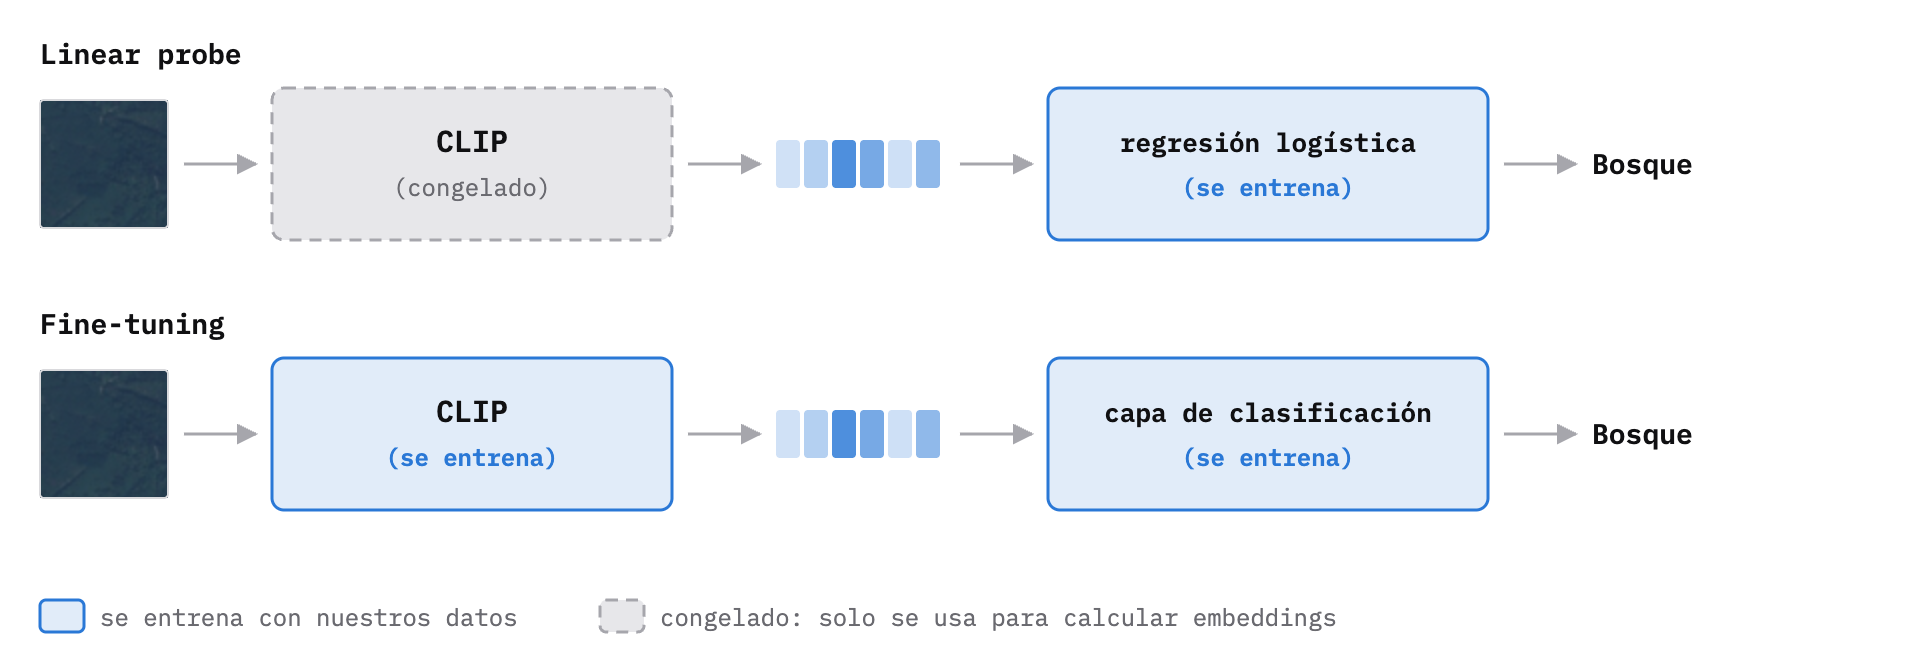

<sub>Qué se entrena en cada caso: en el *linear probe*, CLIP queda congelado y solo aprende la regresión logística.</sub>

In [29]:
# Regresión logística sobre los embeddings, con las 150 imágenes por clase de entrenamiento
clf = LogisticRegression(max_iter=3000)
clf.fit(X_train, y_train)
pred_lr = clf.predict(X_test)
acc_lr = accuracy_score(y_test, pred_lr)

print(f"Exactitud zero-shot:              {acc_zs * 100:.1f}%")
print(f"Exactitud regresión logística:    {acc_lr * 100:.1f}%")
print(f"Exactitud en entrenamiento:       {clf.score(X_train, y_train) * 100:.1f}%")

Exactitud zero-shot:              44.8%
Exactitud regresión logística:    85.8%
Exactitud en entrenamiento:       86.7%


In [30]:
cm_lr = graficar_confusion(y_test, pred_lr, f"Regresión logística sobre embeddings<br><sup>exactitud = {acc_lr * 100:.1f}%</sup>")

In [31]:
# Recall por clase: zero-shot frente a regresión logística
recall_lr = pd.Series(cm_lr.diagonal() / cm_lr.sum(axis=1), index=recall_zs.index)
comparacion = pd.DataFrame({"Zero-shot": recall_zs, "Regresión logística": recall_lr}).sort_values("Regresión logística")

fig = go.Figure()
for metodo, color in [("Zero-shot", GRIS), ("Regresión logística", AZUL)]:
    fig.add_trace(go.Bar(
        x=comparacion[metodo] * 100, y=comparacion.index, orientation="h", name=metodo, marker_color=color,
        hovertemplate="%{y}<br>" + metodo + ": %{x:.0f}%<extra></extra>",
    ))
fig.update_layout(title="¿Qué clases mejoran al entrenar con nuestros datos?", width=760, height=520,
                  barmode="group", bargap=0.25, bargroupgap=0.08,
                  xaxis=dict(title="Recall en prueba (%)", range=[0, 100]), yaxis=dict(showgrid=False),
                  legend=dict(orientation="h", y=-0.15, x=0.5, xanchor="center", traceorder="normal"))
fig.show()

# La misma información en tabla, de mayor a menor mejora
comparacion["Mejora"] = comparacion["Regresión logística"] - comparacion["Zero-shot"]
comparacion.sort_values("Mejora", ascending=False).style.format("{:.0%}")

,Zero-shot,Regresión logística,Mejora
Vegetación herbácea,0%,84%,84%
Cultivo permanente,0%,78%,78%
Río,10%,66%,56%
Pastizal,36%,86%,50%
Mar o lago,56%,94%,38%
Bosque,66%,98%,32%
Residencial,70%,94%,24%
Cultivo anual,66%,88%,22%
Autopista,56%,74%,18%
Industrial,88%,96%,8%


**🔍 ¿Qué observamos?**

- **La exactitud casi se duplica: de 44.8% a 85.8%**, con una regresión logística que se entrena en un par de segundos y sin GPU.
- **Todas las clases mejoran,** y las que más ganan son justamente las que CLIP no reconocía: **Vegetación herbácea pasa de 0% a 84%** y **Cultivo permanente de 0% a 78%**. El modelo general sí "veía" la diferencia (los embeddings la contienen); lo que le faltaba era saber **cómo llamamos nosotros** a cada cosa.
- **Las clases difíciles siguen siendo Río (66%) y Autopista (74%),** las mismas que en el buscador y en el mapa UMAP. Mejorar estas dos requeriría otra información, como imágenes de mayor resolución o las otras bandas del satélite.
- **No hay sobreajuste:** la exactitud de entrenamiento (86.7%) y la de prueba (85.8%) son casi iguales.

> **📖 Definición · Sobreajuste y subajuste**
>
> - **Sobreajuste** (*overfitting*): el modelo memoriza los datos de entrenamiento, incluido su ruido, y falla con datos nuevos. Se detecta cuando la exactitud de entrenamiento es **mucho mayor** que la de prueba.
> - **Subajuste** (*underfitting*): el modelo es demasiado simple para capturar los patrones. Las dos exactitudes son parecidas, pero **bajas**.
>
> Que entrenamiento y prueba estén tan cerca (86.7% y 85.8%) indica que el modelo **no está memorizando**. Incluso sugiere que podría ajustarse un poco más, por ejemplo con un valor mayor de `C` (ver la sección 7.5).

### 6.1 ¿Cuántos datos necesitamos?

Etiquetar imágenes cuesta tiempo y dinero, así que la pregunta práctica es: **¿cuántos ejemplos por clase hacen falta?** Entrenamos el mismo modelo con 1, 2, 5, 10, 20, 50 y 150 imágenes por clase. Como con pocas imágenes el resultado depende mucho de cuáles nos tocan, repetimos cada caso 10 veces con muestras distintas y promediamos.

> **📖 Definición · Curva de aprendizaje**
>
> Una **curva de aprendizaje** muestra cómo cambia el desempeño de un modelo según la **cantidad de datos de entrenamiento**. Sirve para responder preguntas prácticas: ¿vale la pena etiquetar más datos?, ¿a partir de cuántos ejemplos deja de mejorar el modelo? Si la curva todavía sube al final, más datos probablemente ayudarían; si ya se aplanó, conviene buscar mejoras por otro lado (mejores características, otro modelo).

In [32]:
# Curva de aprendizaje: exactitud en prueba según el número de ejemplos por clase
TAMANOS = [1, 2, 5, 10, 20, 50, 150]
REPETICIONES = 10
rng = np.random.default_rng(SEMILLA)

filas = []
for n in TAMANOS:
    for r in range(REPETICIONES if n < 150 else 1):  # con 150 usamos todo el entrenamiento: no hay qué sortear
        idx = np.concatenate([rng.choice(np.where(y_train == k)[0], n, replace=False) for k in range(10)])
        modelo_n = LogisticRegression(max_iter=3000).fit(X_train[idx], y_train[idx])
        filas.append({"por_clase": n, "exactitud": accuracy_score(y_test, modelo_n.predict(X_test))})

curva = pd.DataFrame(filas).groupby("por_clase")["exactitud"].agg(["mean", "std"]).fillna(0)
curva.style.format("{:.1%}")

,mean,std
por_clase,,
1,46.3%,4.3%
2,53.6%,5.6%
5,65.2%,3.7%
10,70.8%,2.0%
20,77.1%,0.7%
50,81.9%,1.1%
150,85.8%,0.0%


In [33]:
n = curva.index.to_numpy()
media, desv = curva["mean"].to_numpy() * 100, curva["std"].to_numpy() * 100

fig = go.Figure()
# Banda de ± una desviación estándar (se dibuja como un polígono: borde superior y luego el inferior al revés)
fig.add_trace(go.Scatter(x=np.r_[n, n[::-1]], y=np.r_[media + desv, (media - desv)[::-1]], fill="toself",
                         mode="lines", fillcolor="rgba(42, 120, 214, 0.15)", line=dict(width=0),
                         hoverinfo="skip", showlegend=False))
fig.add_trace(go.Scatter(
    x=n, y=media, mode="lines+markers", line=dict(color=AZUL, width=2.5), marker=dict(size=9), showlegend=False,
    customdata=desv, hovertemplate="%{x} por clase<br>Exactitud: %{y:.1f}% (± %{customdata:.1f})<extra></extra>",
))
# Etiquetas de valor por encima de la banda, para que no se encimen con ella
for x_i, m_i, d_i in zip(n, media, desv):
    fig.add_annotation(x=np.log10(x_i), y=m_i + d_i, text=f"{m_i:.0f}%", showarrow=False, yshift=12,
                       font=dict(color=TINTA))

# Referencias: zero-shot y azar
fig.add_hline(y=acc_zs * 100, line=dict(color=TINTA, dash="dash", width=1),
              annotation_text=f"Zero-shot ({acc_zs * 100:.0f}%)", annotation_position="bottom right")
fig.add_hline(y=10, line=dict(color=GRIS, dash="dot", width=1),
              annotation_text="Al azar (10%)", annotation_position="top right")

fig.update_layout(
    title="Regresión logística sobre embeddings: exactitud según la cantidad de datos", width=820, height=470,
    xaxis=dict(title="Imágenes etiquetadas por clase (escala logarítmica)", type="log",
               tickvals=TAMANOS, ticktext=[str(t) for t in TAMANOS]),
    yaxis=dict(title="Exactitud en prueba (%)", range=[0, 100]),
)
fig.show()

**🔍 ¿Qué observamos?**

- **Con una sola imagen por clase (10 en total) ya igualamos al *zero-shot*:** 46.3% contra 44.8%.
- **Con 5 por clase llegamos a 65.2%, y con 20 a 77.1%.** Etiquetar 200 imágenes es trabajo de una tarde.
- **Rendimientos decrecientes:** pasar de 1 a 20 imágenes por clase aporta 31 puntos, pero pasar de 20 a 150 (7.5 veces más datos) aporta 8.7.
- **Con pocos datos, importa cuáles nos tocan:** la banda sombreada (± una desviación estándar entre las 10 repeticiones) es ancha con 1 o 2 imágenes por clase y casi desaparece a partir de 20.

### ✏️ Ejercicio 3

La regresión logística no es el único modelo posible sobre los embeddings. Entrena un **k-vecinos más cercanos** (`KNeighborsClassifier`) con `metric="cosine"` y compara su exactitud con la de la regresión logística. ¿Qué relación tiene este modelo con el buscador del bloque 4?

In [34]:
# Tu código aquí

In [35]:
# Solución propuesta: k-NN con distintos valores de k
for k in [1, 5, 15]:
    knn = KNeighborsClassifier(n_neighbors=k, metric="cosine").fit(X_train, y_train)
    print(f"k-NN (k = {k:>2}): exactitud = {accuracy_score(y_test, knn.predict(X_test)) * 100:.1f}%")
print(f"Regresión logística: exactitud = {acc_lr * 100:.1f}%")

k-NN (k =  1): exactitud = 82.6%
k-NN (k =  5): exactitud = 85.0%
k-NN (k = 15): exactitud = 83.0%
Regresión logística: exactitud = 85.8%


**Conclusión del ejercicio:** con k = 5, el k-NN llega a 85.0%, prácticamente igual que la regresión logística (85.8%). Con k = 1 baja a 82.6%, porque depende de un solo vecino, que puede ser engañoso.

La relación con el bloque 4 es directa: **un k-NN es el buscador de imágenes similares, más una votación.** Para clasificar una imagen, busca sus k imágenes más parecidas en el conjunto de entrenamiento y le asigna la clase más común entre ellas.

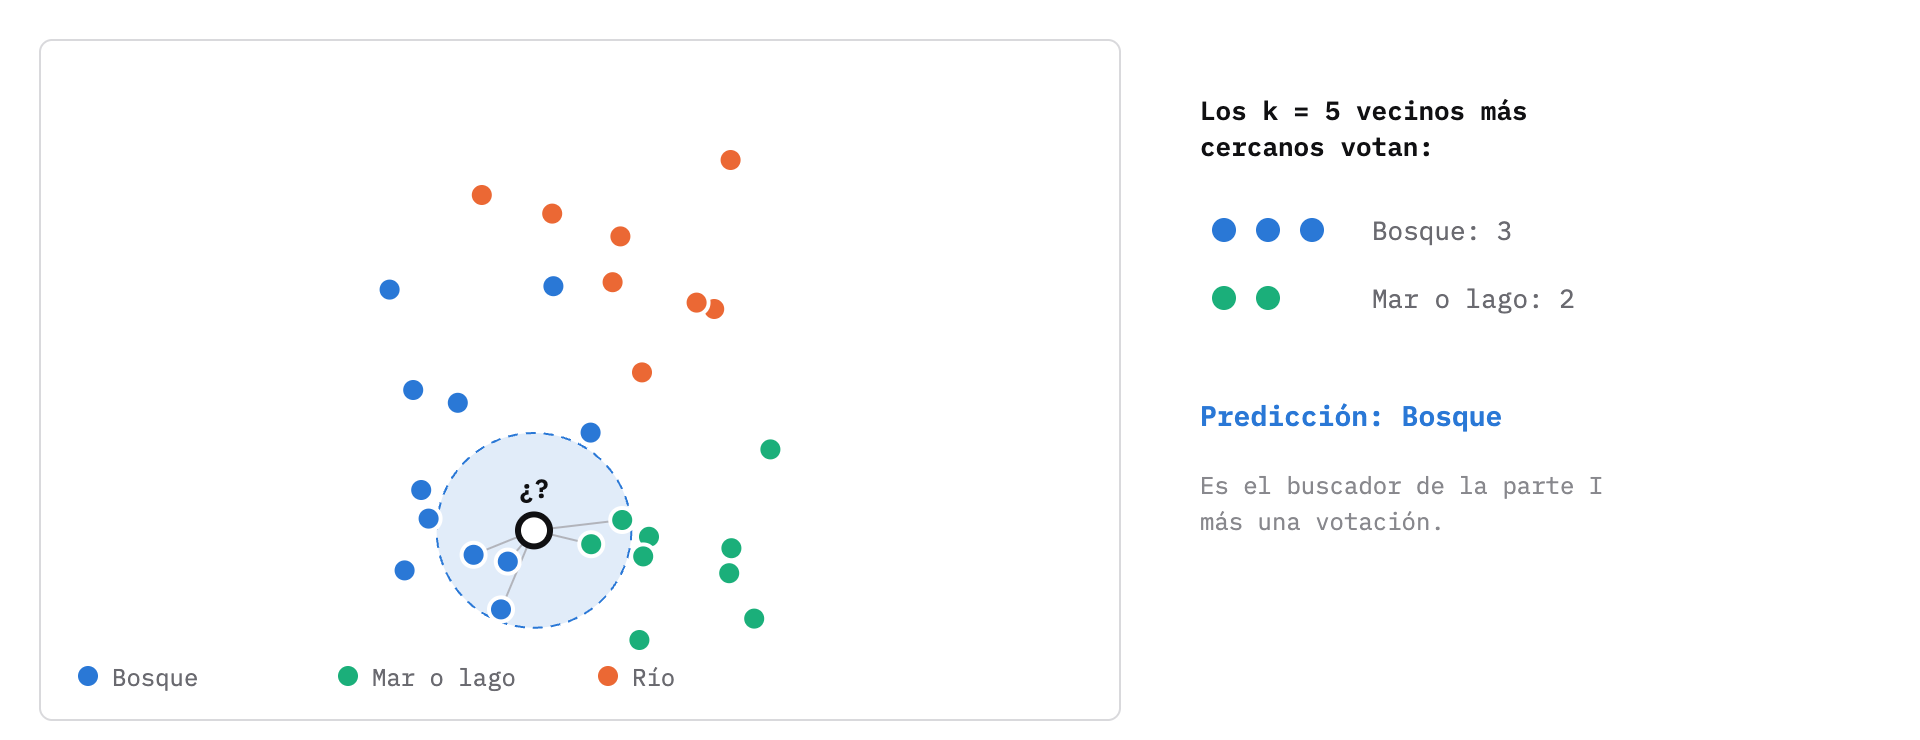

<sub>k-NN con k = 5: los cinco vecinos más cercanos de la consulta votan, y gana la clase más común.</sub>

---

## 7. Búsqueda con texto y cierre

### 7.1 Buscar imágenes escribiendo una frase

Como los textos y las imágenes viven en el mismo espacio, el buscador del bloque 4 también funciona con **una frase como consulta**. Esto es la base de los buscadores semánticos de fotos (por ejemplo, escribir "playa" en la galería de tu teléfono).

> **📖 Definición · Búsqueda semántica y modelos multimodales**
>
> - Una **búsqueda semántica** encuentra resultados por su **significado**, no por coincidencia exacta de palabras. La galería de tu teléfono puede encontrar "playa" aunque ninguna foto tenga esa palabra en su nombre.
> - Un modelo **multimodal** trabaja con más de un tipo de dato (*modalidad*): texto, imágenes, audio. CLIP es multimodal porque pone textos e imágenes en el **mismo espacio**, y por eso podemos comparar una frase con una imagen usando la misma similitud coseno.

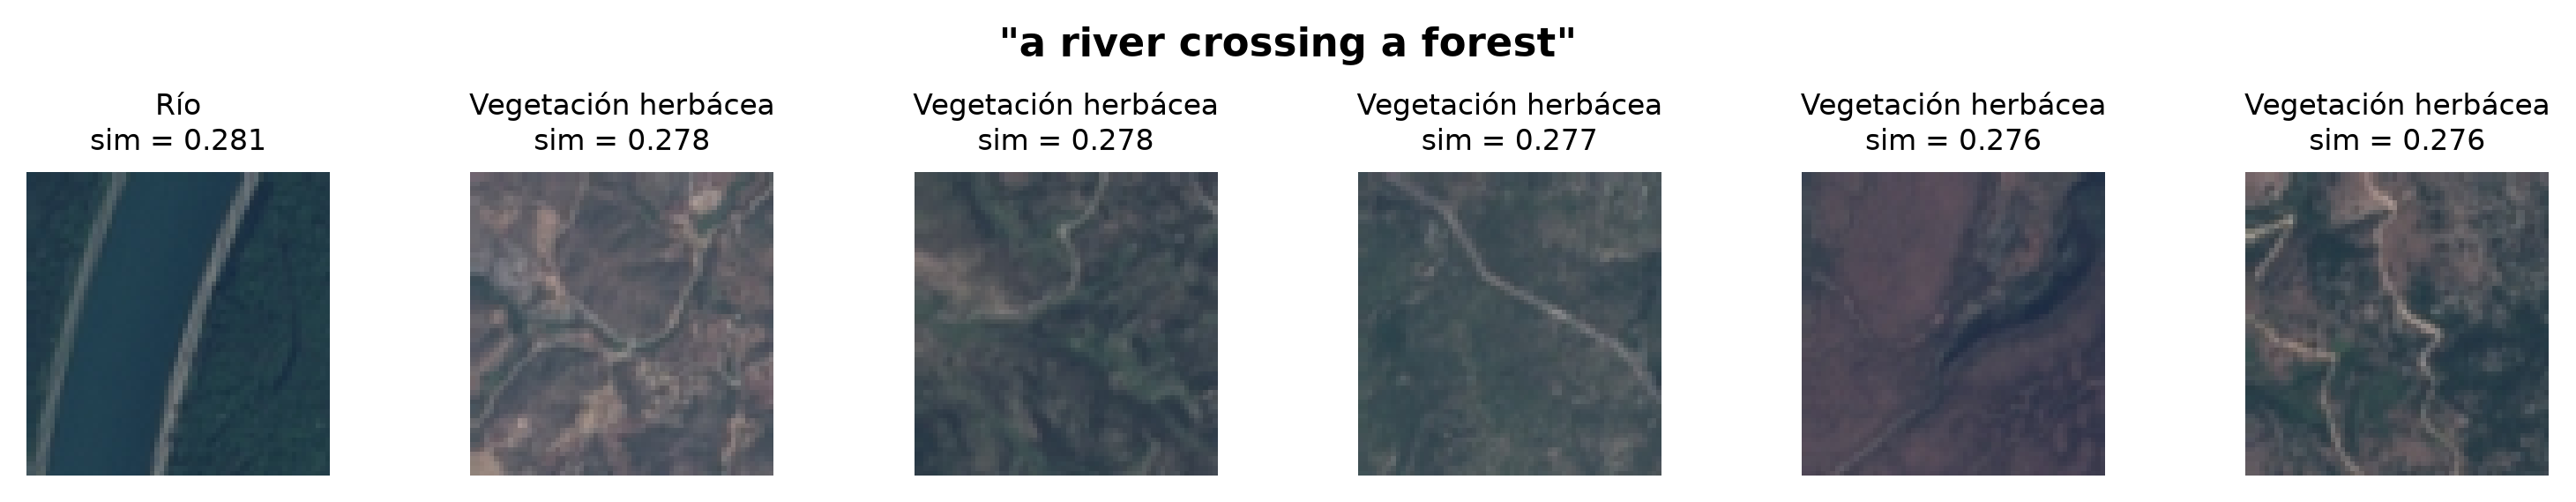

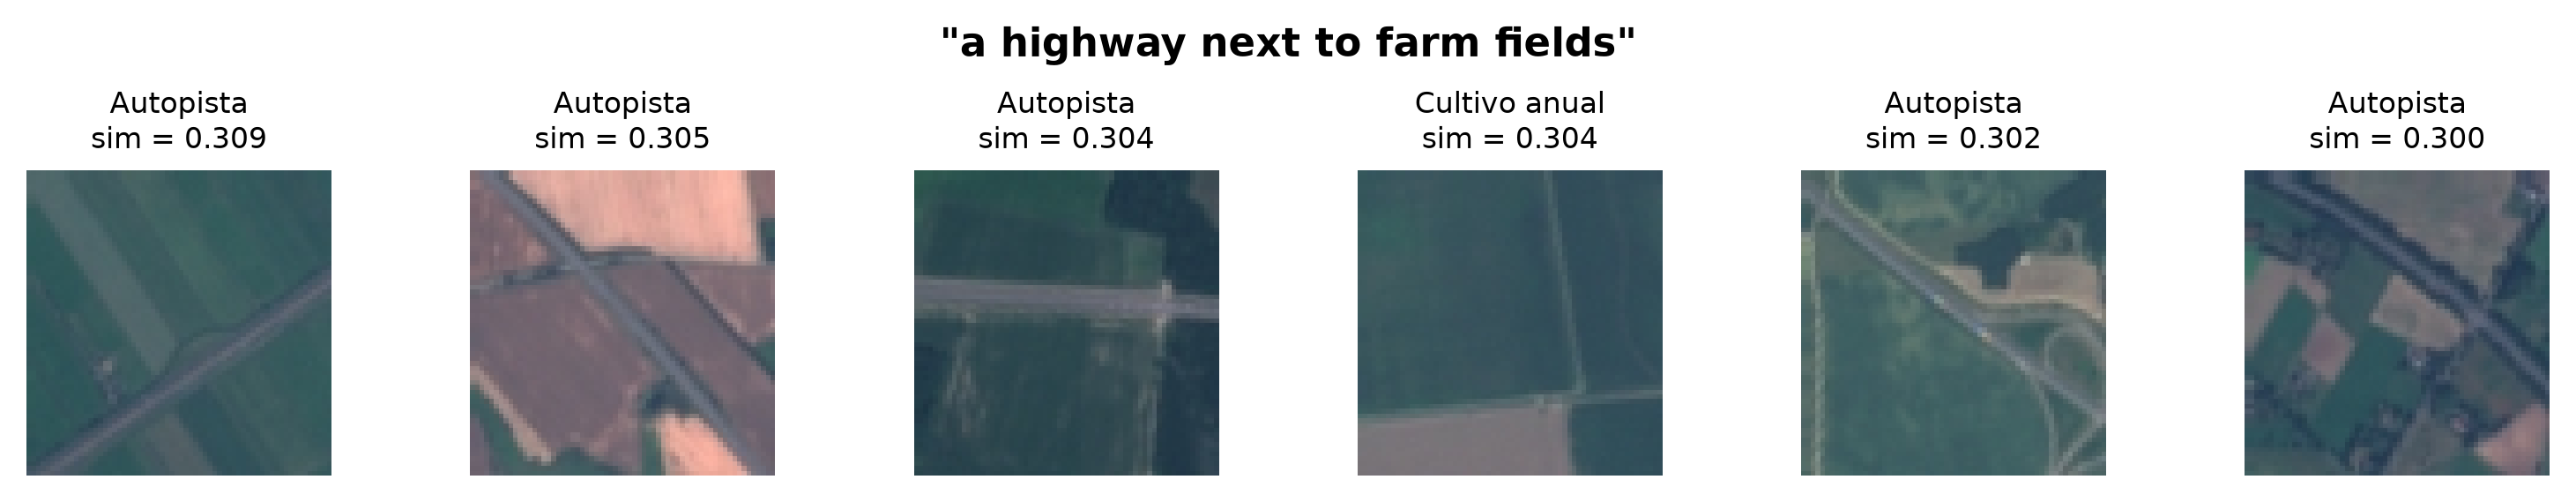

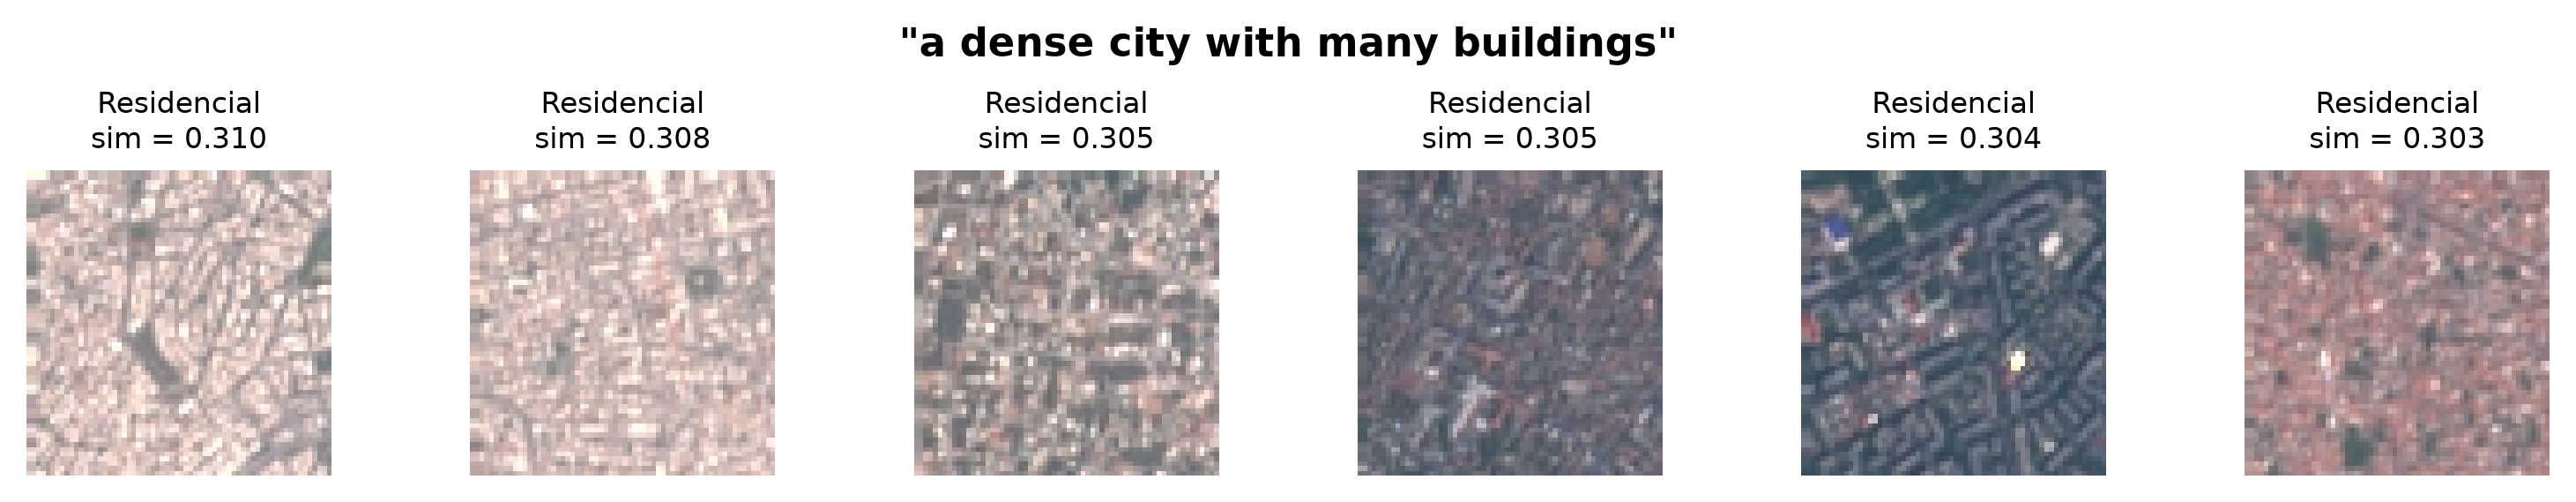

In [36]:
def buscar_por_texto(frase, k=6):
    t = embeddings_de_textos([frase])[0]
    similitudes = X @ t
    mejores = np.argsort(-similitudes)[:k]
    titulos = [f"{df.loc[j, 'clase_es']}\nsim = {similitudes[j]:.3f}" for j in mejores]
    mostrar_imagenes(df.loc[mejores, "ruta"].tolist(), titulos, columnas=k, tam=1.7, suptitulo=f'"{frase}"')


for frase in ["a river crossing a forest", "a highway next to farm fields", "a dense city with many buildings"]:
    buscar_por_texto(frase)

**🔍 ¿Qué observamos?**

- **Las búsquedas funcionan bien cuando la frase describe algo visible:** *"a dense city with many buildings"* devuelve 6 de 6 zonas residenciales, y *"a highway next to farm fields"* devuelve 5 autopistas rodeadas de cultivos.
- **También vemos los límites del modelo:** con *"a river crossing a forest"* solo el primer resultado es un río; los demás son vegetación con caminos sinuosos. Para CLIP, a esta resolución, "una línea que serpentea entre vegetación" es lo más parecido a un río.
- **Las similitudes texto-imagen (≈ 0.3) son mucho más bajas que las de imagen-imagen (≈ 0.95).** Es normal en CLIP: los textos y las imágenes ocupan regiones distintas del espacio compartido. Igual que antes, lo que importa es el **orden**, no el valor absoluto.

### 7.2 Resumen de resultados

In [37]:
resumen = pd.DataFrame([
    {"Método": "Al azar", "Datos etiquetados": "0", "Exactitud": 0.10},
    {"Método": f"Zero-shot: '{PLANTILLAS[0]}'", "Datos etiquetados": "0", "Exactitud": resultados_zs.loc[0, "exactitud"]},
    {"Método": f"Zero-shot: '{MEJOR_PLANTILLA}'", "Datos etiquetados": "0", "Exactitud": acc_zs},
    {"Método": "Regresión logística sobre embeddings", "Datos etiquetados": "5 por clase", "Exactitud": curva.loc[5, "mean"]},
    {"Método": "Regresión logística sobre embeddings", "Datos etiquetados": "20 por clase", "Exactitud": curva.loc[20, "mean"]},
    {"Método": "Regresión logística sobre embeddings", "Datos etiquetados": "150 por clase", "Exactitud": acc_lr},
])
resumen.style.format({"Exactitud": "{:.1%}"}).hide(axis="index")

Método,Datos etiquetados,Exactitud
Al azar,0,10.0%
Zero-shot: '{}',0,36.6%
Zero-shot: 'a centered satellite photo of {}.',0,44.8%
Regresión logística sobre embeddings,5 por clase,65.2%
Regresión logística sobre embeddings,20 por clase,77.1%
Regresión logística sobre embeddings,150 por clase,85.8%


### 7.3 Conclusiones

Volvamos a la pregunta del inicio: **¿basta un modelo de IA general para entender imágenes de un dominio específico?**

- **Para explorar y buscar, sí.** Sin una sola etiqueta, los embeddings de CLIP organizan el dataset por contenido (bloque 3), permiten un buscador con 78.8% de precisión (bloque 4) y hasta buscar con frases (bloque 7).
- **Para clasificar con las categorías de *nuestro* problema, no del todo.** El *zero-shot* se queda en 44.8%, porque el modelo no conoce nuestro vocabulario técnico ni el aspecto de nuestras imágenes.
- **La combinación es lo que mejor funciona:** el modelo general aporta la representación (los embeddings) y nuestros datos aportan el conocimiento del dominio. Con 20 imágenes etiquetadas por clase pasamos de 44.8% a 77.1%, y con 150 a 85.8%, sin entrenar ninguna red neuronal.

**Conexión con la ciencia de datos clásica:** los embeddings son una forma de **ingeniería de características automática**. Una vez que tenemos la tabla de 2,000 × 512, todo lo demás (PCA, división entrenamiento/prueba, regresión logística, k-NN, matriz de confusión) es exactamente lo que se hace con cualquier dataset tabular.

### 7.4 Limitaciones

- **Las imágenes son pequeñas:** CLIP espera imágenes de 224 × 224, así que las de 64 × 64 se amplían y pierden detalle.
- **CLIP se entrenó con fotos de internet,** donde hay pocas imágenes satelitales. Existen modelos del mismo tipo entrenados con imágenes de percepción remota que suelen funcionar mejor en este dominio.
- **Solo usamos 3 de las 13 bandas de Sentinel-2.** Las bandas infrarrojas distinguen muy bien la vegetación, el agua y las zonas construidas.
- **Los datos son de Europa:** antes de usar el modelo en México habría que verificar que funcione con nuestros paisajes, cultivos y ciudades.
- **Trabajamos con una muestra:** 2,000 imágenes y un conjunto de prueba de 500. Los porcentajes pueden variar algunos puntos con otra muestra.

### 7.5 Para seguir explorando

1. **Usa más datos:** cambia `POR_CLASE = 200` por un valor mayor (con GPU, las 27,000 imágenes toman pocos minutos) y repite la curva de aprendizaje.
2. **Ajusta la regresión logística:** prueba distintos valores del parámetro de regularización `C` (por ejemplo, `LogisticRegression(C=10)`) usando validación cruzada.
3. **Busca con tus propias frases:** ¿qué devuelve *"a golf course"* o *"an airport"*? ¿Por qué?
4. **Escala el buscador:** para millones de imágenes se usan bases de datos vectoriales (como FAISS), que encuentran vecinos cercanos sin comparar contra todo el dataset.

### Glosario

| Término | Definición breve |
|---|---|
| **Aprendizaje contrastivo** | Entrenamiento que acerca los vectores de pares correctos (imagen y su texto) y aleja los de pares incorrectos |
| **Aprendizaje por transferencia** | Reutilizar lo que aprendió un modelo en una tarea para resolver otra distinta |
| **Banda espectral** | Rango de longitudes de onda de luz que mide un sensor; Sentinel-2 mide 13 |
| **CLIP** | Modelo de OpenAI (2021) que representa imágenes y textos en un mismo espacio de vectores |
| **Curva de aprendizaje** | Gráfica del desempeño de un modelo según la cantidad de datos de entrenamiento |
| ***Embedding*** | Vector de números que resume el contenido de un dato; contenidos parecidos tienen vectores cercanos |
| **Exactitud** | Proporción de predicciones correctas |
| ***Few-shot*** | Resolver una tarea con unos cuantos ejemplos etiquetados por clase |
| ***Fine-tuning*** | Seguir entrenando un modelo preentrenado con datos nuevos |
| ***Linear probe*** | Entrenar un modelo lineal sencillo sobre los embeddings de un modelo preentrenado congelado |
| **Matriz de confusión** | Tabla que cruza clase real contra clase predicha |
| **PCA** | Reducción de dimensionalidad lineal que conserva las direcciones de mayor varianza |
| **Precisión en k** | Proporción de los primeros k resultados de una búsqueda que son relevantes |
| ***Prompt*** | Texto que se le da a un modelo para indicarle qué queremos |
| **Recall** | De los casos reales de una clase, proporción que el modelo reconoció |
| **Regresión logística** | Modelo de clasificación que convierte sumas ponderadas de las características en probabilidades |
| **Similitud coseno** | Coseno del ángulo entre dos vectores: 1 si apuntan igual, 0 si no tienen relación |
| **Sobreajuste** | Cuando un modelo memoriza los datos de entrenamiento y falla con datos nuevos |
| **UMAP** | Reducción de dimensionalidad no lineal que conserva los vecindarios de los datos |
| **Vision Transformer (ViT)** | Arquitectura que corta la imagen en cuadros y analiza cómo se relacionan entre sí |
| ***Zero-shot*** | Resolver una tarea sin ningún ejemplo etiquetado, solo con una descripción |

### Referencias

- Helber, P., Bischke, B., Dengel, A. y Borth, D. (2019). *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification.* IEEE JSTARS.
- Radford, A. et al. (2021). *Learning Transferable Visual Models From Natural Language Supervision* (CLIP). ICML.
- McInnes, L., Healy, J. y Melville, J. (2018). *UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction.* arXiv:1802.03426.